# Parcial Segundo Corte – Análisis de Datos con Python
**Facultad de Ingeniería Mecatrónica**

## 1. Información de los estudiantes y descripción del problema

**Integrantes:**
- Karen Johanna Garcia Martinez
- Julian Santiago Jimenez Lara

**Descripción del problema:**
La empresa PLADESAN realizó campañas de ensayos mecánicos sobre componentes de una cadena
cardánica durante 2022 y 2024, bajo distintas condiciones de fabricación, materiales y
configuraciones de proceso (fórmula, muestra o contramuestra, cavidad, tiempo, calzas,
temperatura del agua, inyección, entre otras).

Los resultados están en archivos .txt generados por el equipo de ensayo. Como no todos los
ensayos tienen las mismas condiciones, el objetivo es construir un proceso reproducible en
Python que lea, limpie y organice los datos, identifique qué ensayos son comparables entre sí
y permita interpretar los resultados sin sacar conclusiones que los datos no sustenten.


## 2. Obtención del dataset desde Kaggle

El dataset se descarga directamente desde Kaggle con la librería `kagglehub`, usando el
identificador del enlace oficial de la guía. Así el notebook se puede reproducir desde cero
sin subir archivos a mano.

In [1]:
import kagglehub

ruta = kagglehub.dataset_download("kardantel/cardan-shaft-mechanical-test-dataset-2022-and-2024")

print("Dataset descargado en:", ruta)

Using Colab cache for faster access to the 'cardan-shaft-mechanical-test-dataset-2022-and-2024' dataset.
Dataset descargado en: /kaggle/input/cardan-shaft-mechanical-test-dataset-2022-and-2024


## 3. Verificación de archivos e importación de librerías

Se importan las librerías del análisis y se verifica con Python dónde quedó el dataset,
que existan las carpetas de 2022 y 2024, cuántos archivos hay y cómo están organizados.

In [2]:
# 3.1 IMPORTACIÓN DE LIBRERÍAS
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

print("Librerías importadas.")

Librerías importadas.


In [3]:
# 3.2 UBICACIÓN DEL DATASET
ruta_dataset = Path(ruta)

print("UBICACIÓN DEL DATASET")
print("Ruta:", ruta_dataset)
print("¿La carpeta existe?:", ruta_dataset.exists())

UBICACIÓN DEL DATASET
Ruta: /kaggle/input/cardan-shaft-mechanical-test-dataset-2022-and-2024
¿La carpeta existe?: True


In [4]:
#3.3 ESTRUCTURA GENERAL DE DIRECTORIOS
carpetas = [ruta_dataset] + sorted(p for p in ruta_dataset.rglob("*") if p.is_dir())

print("ESTRUCTURA DE DIRECTORIOS\n")
for carpeta in carpetas:
    nivel = len(carpeta.relative_to(ruta_dataset).parts)
    cantidad = sum(1 for p in carpeta.iterdir() if p.is_file())
    print("    " * nivel + carpeta.name + "/", f"({cantidad} archivos)")

ESTRUCTURA DE DIRECTORIOS

cardan-shaft-mechanical-test-dataset-2022-and-2024/ (0 archivos)
    Datos_pruebas_cadena_cardanica_-_Empresa_PLADESAN_-_2022/ (0 archivos)
        Abril_06_-_CADENA_CARDANICA/ (9 archivos)
        Marzo_10_-_Cadena_Cardanica/ (7 archivos)
        Nov._11_-_CADENA_CARDANICA_TENSION/ (4 archivos)
        Octubre_04_-_CADENA_CARDANICA_1400/ (16 archivos)
        Sept._08_-_CADENA_CARDANICA/ (10 archivos)
    Datos_pruebas_cadena_cardanica_-_Empresa_PLADESAN_-_2024/ (0 archivos)
        Abril_26_-_Cadena_Cardanica_1400/ (24 archivos)
        Enero_18_-_Cadena_Cardanica_1400/ (36 archivos)
        Enero_23_-_Cadena_Cardanica_1400/ (10 archivos)
        Feb._06_07_-_Cadena_Cardanica_1400/ (26 archivos)
        Feb._27_-_Cadena_Cardanica_1400/ (21 archivos)
        Marzo_15_-_Cadena_Cardanica_1400/ (16 archivos)
        Marzo_19_-_Cadena_Cardanica_1400/ (8 archivos)


In [5]:
# 3.4 VERIFICACIÓN DE LAS CARPETAS 2022 Y 2024
subcarpetas = carpetas[1:]   # se excluye la raíz porque su nombre contiene ambos años

print("CARPETAS POR AÑO\n")
for anio in ["2022", "2024"]:
    encontradas = [p for p in subcarpetas if anio in p.name]
    print(f"Carpetas que contienen '{anio}': {len(encontradas)}")
    for c in encontradas:
        print("   ", c.relative_to(ruta_dataset))

CARPETAS POR AÑO

Carpetas que contienen '2022': 1
    Datos_pruebas_cadena_cardanica_-_Empresa_PLADESAN_-_2022
Carpetas que contienen '2024': 1
    Datos_pruebas_cadena_cardanica_-_Empresa_PLADESAN_-_2024


In [6]:
# 3.5 CANTIDAD DE ARCHIVOS
archivos = sorted(p for p in ruta_dataset.rglob("*") if p.is_file())

lista_archivos = pd.DataFrame({
    "Ruta": [str(p.relative_to(ruta_dataset)) for p in archivos],
    "Extension": [p.suffix.lower() for p in archivos]
})

print("CANTIDAD DE ARCHIVOS")
print("Total de archivos:", len(lista_archivos))

print("\nARCHIVOS POR EXTENSIÓN")
display(lista_archivos["Extension"].value_counts().to_frame("Cantidad"))

CANTIDAD DE ARCHIVOS
Total de archivos: 187

ARCHIVOS POR EXTENSIÓN


,Cantidad
Extension,
.txt,158
.pdf,26
.mai,3


In [7]:
# 3.6 ARCHIVOS POR AÑO, CAMPAÑA Y EXTENSIÓN
lista_archivos["Año"] = [re.search(r"20\d\d", p.relative_to(ruta_dataset).parts[0]).group() for p in archivos]
lista_archivos["Campaña"] = [p.parent.name for p in archivos]

tabla_archivos = pd.crosstab(
    [lista_archivos["Año"], lista_archivos["Campaña"]],
    lista_archivos["Extension"],
    margins=True,
    margins_name="Total"
)

print("ARCHIVOS POR AÑO, CAMPAÑA Y EXTENSIÓN")
display(tabla_archivos)

ARCHIVOS POR AÑO, CAMPAÑA Y EXTENSIÓN


Extension                                 .mai  .pdf  .txt  Total
Año   Campaña                                                    
2022  Abril_06_-_CADENA_CARDANICA            0     0     9      9
      Marzo_10_-_Cadena_Cardanica            1     0     6      7
      Nov._11_-_CADENA_CARDANICA_TENSION     1     0     3      4
      Octubre_04_-_CADENA_CARDANICA_1400     0     0    16     16
      Sept._08_-_CADENA_CARDANICA            0     0    10     10
2024  Abril_26_-_Cadena_Cardanica_1400       0     0    24     24
      Enero_18_-_Cadena_Cardanica_1400       1     0    35     36
      Enero_23_-_Cadena_Cardanica_1400       0     0    10     10
      Feb._06_07_-_Cadena_Cardanica_1400     0    26     0     26
      Feb._27_-_Cadena_Cardanica_1400        0     0    21     21
      Marzo_15_-_Cadena_Cardanica_1400       0     0    16     16
      Marzo_19_-_Cadena_Cardanica_1400       0     0     8      8
Total                                        3    26   158    187

**Observación:** el dataset está organizado en carpetas por año (2022 y 2024) y, dentro de
cada año, en carpetas por campaña de ensayo. 2022 tiene 5 campañas y 2024 tiene 7.
El nombre de cada campaña incluye la fecha y, en algunos casos, información adicional como
el tipo de ensayo (TENSION) o la referencia 1400. Los nombres no tienen un formato uniforme
(mayúsculas/minúsculas, meses abreviados, campañas de dos días), por lo que deberán
normalizarse antes de usarlos como variables.


**Observación:** de los 187 archivos, 158 son .txt (44 de 2022 y 114 de 2024).
La campaña Feb. 06-07 de 2024 contiene únicamente archivos .pdf, por lo que no puede
procesarse de forma automatizada; en la práctica, 2024 cuenta con 6 campañas con datos .txt.
Las campañas tienen tamaños muy diferentes (entre 3 y 35 archivos .txt), lo cual debe
tenerse en cuenta al comparar resultados entre ellas.


## 4. Reconocimiento del conjunto de datos y lectura automatizada

Se revisan los nombres de los archivos .txt para identificar qué información del ensayo
contienen (fórmula, muestra, cavidad, tiempo, condición, tipo de ensayo).

In [8]:
# 4.1 NOMBRES DE LOS ARCHIVOS .TXT POR CAMPAÑA
txt = lista_archivos[lista_archivos["Extension"] == ".txt"]

print("TOTAL DE ARCHIVOS .TXT:", len(txt))
for (anio, campana), grupo in txt.groupby(["Año", "Campaña"]):
    print(f"\n{anio} | {campana} ({len(grupo)} archivos)")
    for ruta_txt in grupo["Ruta"]:
        print("   ", Path(ruta_txt).name)

TOTAL DE ARCHIVOS .TXT: 158

2022 | Abril_06_-_CADENA_CARDANICA (9 archivos)
    PLADESAN_1391_-_MUESTRA_1.txt
    PLADESAN_1391_-_MUESTRA_2.txt
    PLADESAN_HEBILLA_MOLDE_ANTERIOR_-_MUESTRA_8.txt
    PLADESAN_HEBILLA_MOLDE_NUEVO_-_MUESTRA_9.txt
    PLADESAN_LOTE_ACTUAL_-_MUESTRA_3.txt
    PLADESAN_LOTE_ACTUAL_-_MUESTRA_4.txt
    PLADESAN_PC21_-_MUESTRA_5.txt
    PLADESAN_PC21_-_MUESTRA_6.txt
    PLADESAN_PC21_-_PATRON_-_MUESTRA_7.txt

2022 | Marzo_10_-_Cadena_Cardanica (6 archivos)
    LOTE_ACTUAL_-_PROBETA_2.txt
    LOTE_ACTUAL_-_PROBETA_3.txt
    LOTE_ANTERIOR_-_PROBETA_1.txt
    LOTE_ANTERIOR_-_PROBETA_2.txt
    LOTE_ANTERIOR_-_PROBETA_3.txt
    PATRON_DE_REFERENCIA.txt

2022 | Nov._11_-_CADENA_CARDANICA_TENSION (3 archivos)
    CADENA_Cardanica_1400_-_Muestra_1_-_Patron_de_Referencia.txt
    CADENA_Cardanica_1400_-_Muestra_2_-_Homologacion_de_Material.txt
    CADENA_Cardanica_1400_-_Muestra_3_-_Homologacion_TAB.txt

2022 | Octubre_04_-_CADENA_CARDANICA_1400 (16 archivos)
    FORMU

**Observación sobre los nombres de los archivos:** los nombres contienen información del
ensayo (fórmula, número de muestra, cavidad, tiempo de procesamiento y condición), pero no
siguen un formato único: cambian las mayúsculas, los separadores, las abreviaturas
(CAV. / CAVIDAD) y la forma de nombrar la muestra (MUESTRA / Muestra / PROBETA).

Además, los archivos corresponden a distintos componentes (pin, piñón, hebilla, cadena 1400
y cadena 2600), distintos tipos de ensayo (tensión y compresión) y distintas condiciones
(patrón, contramuestra, lote, molde, uso de calzas, temperatura del agua, temperatura y
velocidad de inyección). Esto indica que los archivos no son repeticiones de un mismo
experimento.


In [9]:
# 4.2 CONTENIDO DE UN ARCHIVO DE EJEMPLO POR AÑO
def leer_lineas(ruta_archivo):
    try:
        return ruta_archivo.read_text(encoding="utf-8").splitlines()
    except UnicodeDecodeError:
        return ruta_archivo.read_text(encoding="latin-1").splitlines()

ejemplos = txt.groupby("Año")["Ruta"].first()

for anio, ruta_txt in ejemplos.items():
    lineas = leer_lineas(ruta_dataset / ruta_txt)
    print(f"\nARCHIVO DE EJEMPLO {anio}: {Path(ruta_txt).name}")
    print("Total de líneas:", len(lineas), "\n")
    for i, linea in enumerate(lineas[:40]):
        print(f"{i:>3} | {linea}")


ARCHIVO DE EJEMPLO 2022: PLADESAN_1391_-_MUESTRA_1.txt
Total de líneas: 3073 

  0 | Test Name	Test Mode	Test Type	Control	Test Speed 1	Test Speed 2	Test Speed 3	Change Point 1	Change Point 2	Disp. Origin	Break and Limit Action	Sensitivity:	Level:	
  1 | 	Single	Tensile	Stroke	 5 	 1 	 1 	Off	Off	Start	Stop	 0 	 0 	
  2 | Title	Sub title	Comment
  3 | USTA - Facultad de Ingenieria Mecatronica Laboratorio de Caracterizaciòn de Materiales 	PLADESAN - Curva Fuerza Vs. Alargamiento - Cadena Cardanica 1400. 06.04.2022.
  4 | PLADESAN 1391
  5 | Muestra # 1
  6 | 
  7 | 
  8 | Shape:	Batch Size:	SubBatch Size:	
  9 | Plate	 1 	 1 	
 10 | Name:	Thickness	Width	Gauge Length	
 11 | Size Unit:	mm	mm	mm	
 12 |  1 - 1	1,0000	1,0000	100,0000	
 13 | 
 14 | Name	YP_Force	Max_Force	Break_Force	Break_Disp	Break_Stress	Break_Strain	Max_Disp	Max_Stress	Max_Strain	YP_Disp	YP_Stress	YP_Strain	
 15 | Parameter	0,1 %/FS	 	 	 	 	 	 	 	 	0,1 %/FS	0,1 %/FS	0,1 %/FS	
 16 | Units	kN	kN	kN	mm	N/mm2	%	mm	N/mm2	%	m

**Observación sobre el contenido de los archivos:** cada .txt tiene un encabezado con la
configuración del ensayo, títulos y comentarios (fecha, referencia, condición), geometría
de la probeta, una fila de resultados resumen (YP_Force, Max_Force, Max_Disp, etc.) y
finalmente el registro experimental.

- Los archivos de 2022 están en inglés (Time | Force | Stroke) y los de 2024 en español
  (Tiempo | Carga | Alargamiento); deben unificarse.
- Los números usan coma decimal y el código "-.-" representa valores no disponibles.
- La posición del bloque de datos cambia entre archivos, por lo que debe detectarse
  automáticamente.
- La geometría registrada (1 mm x 1 mm, 100 mm) no corresponde a la pieza real, por lo que
  los valores de esfuerzo (Stress) y deformación (Strain) calculados por el equipo no son
  interpretables físicamente. El análisis se basa en Fuerza (kN) y Desplazamiento (mm).
  

In [10]:
# 4.3 REVISIÓN DE LA ESTRUCTURA DE TODOS LOS ARCHIVOS .TXT
def revisar_estructura(ruta_archivo):
    lineas = leer_lineas(ruta_archivo)
    info = {
        "Total_Lineas": len(lineas),
        "Tipo_Ensayo_Equipo": np.nan,
        "Linea_Resumen": np.nan,
        "Linea_Datos": np.nan,
        "Columnas_Datos": np.nan
    }

    # Línea 1: configuración del ensayo, el tipo está en la tercera posición
    if len(lineas) > 1:
        valores = lineas[1].split("\t")
        if len(valores) > 2:
            info["Tipo_Ensayo_Equipo"] = valores[2].strip()

    for i, linea in enumerate(lineas):
        primera = linea.split("\t")[0].strip()
        if primera in ("Name", "Nombre") and "Max_Force" in linea:
            info["Linea_Resumen"] = i
        if primera in ("Time", "Tiempo"):
            info["Linea_Datos"] = i
            info["Columnas_Datos"] = " | ".join(c.strip() for c in linea.split("\t") if c.strip())
            break

    return info


estructura = pd.DataFrame([revisar_estructura(ruta_dataset / r) for r in txt["Ruta"]])
estructura.insert(0, "Archivo", [Path(r).name for r in txt["Ruta"]])
estructura.insert(0, "Campaña", txt["Campaña"].values)
estructura.insert(0, "Año", txt["Año"].values)

print("TIPO DE ENSAYO SEGÚN EL EQUIPO")
display(pd.crosstab([estructura["Año"], estructura["Campaña"]],
                    estructura["Tipo_Ensayo_Equipo"].fillna("No encontrado")))

print("\nCOLUMNAS DEL REGISTRO EXPERIMENTAL")
display(estructura["Columnas_Datos"].value_counts(dropna=False).to_frame("Cantidad"))

print("\nLÍNEA DONDE EMPIEZAN LOS DATOS")
display(estructura["Linea_Datos"].value_counts(dropna=False).to_frame("Cantidad"))

print("\nARCHIVOS SIN BLOQUE DE DATOS")
display(estructura[estructura["Linea_Datos"].isna()])

TIPO DE ENSAYO SEGÚN EL EQUIPO


Tipo_Ensayo_Equipo                       Comp.  Tensile  Traccion
Año  Campaña                                                     
2022 Abril_06_-_CADENA_CARDANICA             0        9         0
     Marzo_10_-_Cadena_Cardanica             0        6         0
     Nov._11_-_CADENA_CARDANICA_TENSION      0        3         0
     Octubre_04_-_CADENA_CARDANICA_1400      7        9         0
     Sept._08_-_CADENA_CARDANICA             5        5         0
2024 Abril_26_-_Cadena_Cardanica_1400        0        0        24
     Enero_18_-_Cadena_Cardanica_1400        0       35         0
     Enero_23_-_Cadena_Cardanica_1400        0       10         0
     Feb._27_-_Cadena_Cardanica_1400         0        0        21
     Marzo_15_-_Cadena_Cardanica_1400        0        0        16
     Marzo_19_-_Cadena_Cardanica_1400        0        0         8


COLUMNAS DEL REGISTRO EXPERIMENTAL


,Cantidad
Columnas_Datos,
Time | Force | Stroke,89
Tiempo | Carga | Alargamiento,69



LÍNEA DONDE EMPIEZAN LOS DATOS


,Cantidad
Linea_Datos,
23,48
24,48
25,18
21,18
22,17
20,9



ARCHIVOS SIN BLOQUE DE DATOS


,Año,Campaña,Archivo,Total_Lineas,Tipo_Ensayo_Equipo,Linea_Resumen,Linea_Datos,Columnas_Datos


**Observación sobre la estructura de los archivos:** los 158 archivos contienen un bloque de
datos experimentales con solo dos variantes de columnas: Time | Force | Stroke (89 archivos,
en inglés) y Tiempo | Carga | Alargamiento (69 archivos, en español). El idioma no depende del
año sino de la campaña (Enero 18 y 23 de 2024 están en inglés), por lo que se detecta archivo
por archivo.

Según el encabezado, 146 ensayos son de tensión (Tensile / Traccion) y 12 de compresión (Comp.),
todos de 2022. En la campaña Sept. 08 hay 5 ensayos de compresión cuyo nombre no lo indica, por
lo que el tipo de ensayo se obtiene del contenido del archivo y no del nombre.

El bloque de datos empieza entre las líneas 20 y 25, por lo que su posición se detecta
automáticamente.

In [11]:
# 4.4 ENSAYOS DE COMPRESIÓN Y FILA DE RESUMEN
print("ENSAYOS DE COMPRESIÓN")
print(estructura[estructura["Tipo_Ensayo_Equipo"] == "Comp."][["Campaña", "Archivo"]].to_string())

print("\nARCHIVOS SIN FILA DE RESUMEN:", estructura["Linea_Resumen"].isna().sum())

ENSAYOS DE COMPRESIÓN
                               Campaña                                                     Archivo
27  Octubre_04_-_CADENA_CARDANICA_1400         PIN_1400_-_COMPRESION_-_FORMULA_1_-_MUESTRA_1.2.txt
28  Octubre_04_-_CADENA_CARDANICA_1400         PIN_1400_-_COMPRESION_-_FORMULA_1_-_MUESTRA_1.3.txt
29  Octubre_04_-_CADENA_CARDANICA_1400         PIN_1400_-_COMPRESION_-_FORMULA_1_-_MUESTRA_1.4.txt
30  Octubre_04_-_CADENA_CARDANICA_1400           PIN_1400_-_COMPRESION_-_FORMULA_1_-_MUESTRA_1.txt
31  Octubre_04_-_CADENA_CARDANICA_1400         PIN_1400_-_COMPRESION_-_FORMULA_2_-_MUESTRA_2.2.txt
32  Octubre_04_-_CADENA_CARDANICA_1400         PIN_1400_-_COMPRESION_-_FORMULA_2_-_MUESTRA_2.3.txt
33  Octubre_04_-_CADENA_CARDANICA_1400           PIN_1400_-_COMPRESION_-_FORMULA_2_-_MUESTRA_2.txt
34         Sept._08_-_CADENA_CARDANICA                 Muestra_1.1._PIN_CADENA._2a._EXTRACCION.txt
35         Sept._08_-_CADENA_CARDANICA                 Muestra_1.2._PIN_CADENA._3a._EXT

### 4.5 Construcción del inventario de ensayos

Se construye una tabla con una fila por archivo .txt. La información se obtiene de tres fuentes:
- **Carpeta:** año y campaña.
- **Nombre del archivo:** fórmula, muestra, cavidad, tiempo de procesamiento, contramuestra,
  componente y condición. Se usan expresiones regulares porque los nombres no tienen un formato
  único (MUESTRA / Muestra / PROBETA, CAV. / CAVIDAD).
- **Contenido del archivo:** tipo de ensayo (Tensile / Traccion / Comp.), referencia de la cadena
  y condición cuando el nombre no la indica.

Decisiones:
- Cuando una variable no aparece en el nombre, se registra como NaN.
- Muestra se guarda como texto porque es un identificador (1.1, 2B), no una cantidad.
- Condición corresponde al texto del nombre que queda después de quitar las demás variables.
  Si el nombre no indica ninguna condición, se busca en los comentarios del encabezado una línea
  con las palabras que describen condiciones de proceso en los nombres de otros archivos (TEMP,
  SALIDA DE AIRE, CALZAS, ESTANDAR, INYECCION, AGUA). La columna Fuente_Condición indica si la
  condición se obtuvo del nombre o del encabezado.
- Se agregan Componente, Referencia y Contramuestra porque son necesarias para decidir qué
  ensayos son comparables.

In [ ]:
# 4.5 FUNCIONES PARA EXTRAER LA INFORMACIÓN DE CADA ARCHIVO
PATRON_FORMULA = r"\bFORMULA\s*(\d+)"
PATRON_MUESTRA = r"\b(?:MUESTRA|PROBETA)\s*(\d+(?:\.\d+)*[A-Z]?)"
PATRON_CAVIDAD = r"\b(?:CAVIDAD|CAV\.?)\s*(\d+(?:X\d+)?)"
PATRON_TIEMPO = r"\b(\d+)\s*MINUTOS\b"
PATRON_COMPONENTE = r"\b(HEBILLA|PINON 1400|PIN 1400|PIN CADENA|CADENA 2600)\b"

# Palabras que describen condiciones de proceso en los nombres de los archivos de 2024
PATRON_CONDICION_ENCABEZADO = r"TEMP|SALIDA DE AIRE|CALZAS|EST[AÁ]NDAR|INYECCI|AGUA"

COMPONENTES = {
    "HEBILLA": "Hebilla",
    "PINON 1400": "Piñón",
    "PIN 1400": "Pin",
    "PIN CADENA": "Pin",
    "CADENA 2600": "Cadena"
}

TIPOS_ENSAYO = {
    "Tensile": "Tensión",
    "Traccion": "Tensión",
    "Comp.": "Compresión"
}

PATRONES_A_QUITAR = [
    r"\bPLADESAN\b", PATRON_FORMULA, PATRON_MUESTRA, PATRON_CAVIDAD, PATRON_TIEMPO,
    PATRON_COMPONENTE, r"\bCADENA CARDANICA \d{4}\b", r"\bCONTRAMUESTRA\b", r"\bCOMPRESION\b"
]


def buscar(patron, texto):
    """Retorna lo que encuentra el patrón en el texto. Si no lo encuentra, retorna NaN."""
    resultado = re.search(patron, texto)
    return resultado.group(1) if resultado else np.nan


def extraer_condicion(nombre):
    """Quita del nombre las variables ya extraídas y retorna el texto que queda."""
    resto = nombre
    for patron in PATRONES_A_QUITAR:
        resto = re.sub(patron, " ", resto)
    resto = re.sub(r"[-.]", " ", resto)
    resto = re.sub(r"\s+", " ", resto).strip()
    return resto if resto else np.nan


def condicion_encabezado(lineas):
    """Busca la condición en los comentarios del encabezado (entre el título y la forma de la
    probeta). Retorna la primera línea que menciona una condición de proceso; si no hay, NaN."""
    for linea in lineas[2:]:
        primera = linea.split("\t")[0].strip()
        if primera in ("Shape:", "Forma:"):
            break
        texto = " ".join(p.strip() for p in linea.split("\t") if p.strip()).upper()
        if primera not in ("Title", "Titulo") and re.search(PATRON_CONDICION_ENCABEZADO, texto):
            texto = re.sub(r"[^\w\s.\-]", " ", texto.replace("°", ""))   # quita símbolos como + y °
            return extraer_condicion(texto)
    return np.nan


def extraer_info(ruta_archivo):
    """Obtiene la información del ensayo a partir de la carpeta, el nombre y el contenido."""
    relativa = ruta_archivo.relative_to(ruta_dataset)
    nombre = ruta_archivo.stem.upper().replace("_", " ")
    lineas = leer_lineas(ruta_archivo)
    encabezado = " ".join(lineas[:20]).upper()

    componente = buscar(PATRON_COMPONENTE, nombre)

    # La referencia se busca primero en el nombre y, si no aparece, en el encabezado
    referencia = buscar(r"\b(1400|2600)\b", nombre)
    if pd.isna(referencia):
        referencia = buscar(r"CARD[AÁ]NICA\s*(\d{4})", encabezado)

    # La condición se busca primero en el nombre y, si no aparece, en el encabezado
    condicion = extraer_condicion(nombre)
    fuente_condicion = "Nombre"
    if pd.isna(condicion):
        condicion = condicion_encabezado(lineas)
        fuente_condicion = "Encabezado" if pd.notna(condicion) else np.nan

    tipo_equipo = lineas[1].split("\t")[2].strip()

    return {
        "Año": re.search(r"20\d\d", relativa.parts[0]).group(),
        "Campaña": relativa.parts[1],
        "Archivo": ruta_archivo.name,
        "Componente": COMPONENTES.get(componente, "Cadena"),
        "Referencia": referencia,
        "Fórmula": buscar(PATRON_FORMULA, nombre),
        "Muestra": buscar(PATRON_MUESTRA, nombre),
        "Contramuestra": "CONTRAMUESTRA" in nombre,
        "Cavidad": buscar(PATRON_CAVIDAD, nombre),
        "Tiempo_min": buscar(PATRON_TIEMPO, nombre),
        "Condición": condicion,
        "Fuente_Condición": fuente_condicion,
        "Tipo_Ensayo": TIPOS_ENSAYO.get(tipo_equipo, tipo_equipo),
        "Ruta": str(relativa)
    }

print("Funciones de extracción definidas.")

In [ ]:
# 4.6 CONSTRUCCIÓN DEL INVENTARIO DE ENSAYOS
rutas_txt = [ruta_dataset / r for r in txt["Ruta"]]

inventario_ensayos = pd.DataFrame([extraer_info(r) for r in rutas_txt])
inventario_ensayos["Tiempo_min"] = pd.to_numeric(inventario_ensayos["Tiempo_min"])

print("INVENTARIO DE ENSAYOS")
print("Filas:", inventario_ensayos.shape[0], "| Columnas:", inventario_ensayos.shape[1])
print(inventario_ensayos.drop(columns="Ruta").head(10).to_string())

faltantes = inventario_ensayos.isnull().sum()
print("\nVALORES FALTANTES POR VARIABLE")
print(pd.DataFrame({
    "Faltantes": faltantes,
    "Porcentaje (%)": (faltantes / len(inventario_ensayos) * 100).round(1)
}).to_string())

print("\nFUENTE DE LA CONDICIÓN POR CAMPAÑA")
print(pd.crosstab(inventario_ensayos["Campaña"],
                  inventario_ensayos["Fuente_Condición"].fillna("Sin condición")).to_string())

**Observación sobre los valores faltantes del inventario:** los valores faltantes no son
errores de lectura, sino que reflejan el diseño de cada campaña. La cavidad no se registró
en ningún ensayo de 2022; la fórmula solo se identifica en Octubre 2022 y Abril 2024; y el
tiempo de procesamiento solo se varió en cuatro campañas de 2024. La condición de los 24
ensayos de marzo de 2024 no aparece en el nombre del archivo, pero sí en el encabezado
("TEMP. 210°C + SALIDA DE AIRE - AZUL"), por lo que se recuperó de allí; los 18 faltantes
restantes son de 2022 (16 de octubre, donde lo que cambia entre ensayos es la fórmula, y 2 de
septiembre). Por lo tanto, un NaN en estas variables significa "no aplica o no se registró en
esa campaña", y no debe imputarse con un valor inventado.

In [14]:
# 4.7 VERIFICACIÓN DE LAS VARIABLES EXTRAÍDAS
print("COMPONENTE Y REFERENCIA VS TIPO DE ENSAYO")
print(pd.crosstab(
    [inventario_ensayos["Componente"], inventario_ensayos["Referencia"].fillna("NaN")],
    inventario_ensayos["Tipo_Ensayo"]
).to_string())

print("\nARCHIVOS SIN REFERENCIA")
print(inventario_ensayos[inventario_ensayos["Referencia"].isna()][["Campaña", "Archivo"]].to_string())

print("\nCAVIDADES")
print(inventario_ensayos["Cavidad"].value_counts(dropna=False).to_string())

print("\nTIEMPOS (min)")
print(inventario_ensayos["Tiempo_min"].value_counts(dropna=False).sort_index().to_string())

print("\nCONDICIONES POR CAMPAÑA")
for (anio, campana), grupo in inventario_ensayos.groupby(["Año", "Campaña"]):
    print(f"\n{anio} | {campana}")
    print(grupo["Condición"].value_counts(dropna=False).to_string())

COMPONENTE Y REFERENCIA VS TIPO DE ENSAYO
Tipo_Ensayo            Compresión  Tensión
Componente Referencia                     
Cadena     1400                 0      136
           2600                 0        6
Hebilla    NaN                  0        2
Pin        1400                12        0
Piñón      1400                 0        2

ARCHIVOS SIN REFERENCIA
                       Campaña                                          Archivo
2  Abril_06_-_CADENA_CARDANICA  PLADESAN_HEBILLA_MOLDE_ANTERIOR_-_MUESTRA_8.txt
3  Abril_06_-_CADENA_CARDANICA     PLADESAN_HEBILLA_MOLDE_NUEVO_-_MUESTRA_9.txt

CAVIDADES
Cavidad
1      47
NaN    44
2      43
2X3     8
1X3     8
1X1     4
2X1     4

TIEMPOS (min)
Tiempo_min
0.0      12
15.0      6
30.0      6
45.0     12
60.0      6
75.0      8
90.0      2
105.0     2
120.0     7
NaN      97

CONDICIONES POR CAMPAÑA

2022 | Abril_06_-_CADENA_CARDANICA
Condición
1391              2
LOTE ACTUAL       2
PC21              2
MOLDE ANTERIOR    1
MOLDE 

**Observación sobre las variables extraídas:** el conjunto contiene 136 ensayos de tensión de
la cadena 1400, 6 de la cadena 2600, 12 de compresión del pin, 2 de piñón y 2 de hebilla.
Solo los ensayos del mismo componente y tipo de ensayo son candidatos a compararse.

Las cavidades 1X3, 2X3, 1X1 y 2X1 (Marzo 2024) usan una notación diferente cuyo significado
no está documentado, por lo que se conservan como categorías independientes.

Las condiciones presentan variantes de escritura (HOMOLOGACION DE MATERIAL / HOMOLOGACION
MATERIAL) y nombres distintos para la condición de referencia en cada campaña (NORMAL
ESTANDAR, DISENO ESTANDAR, REGULAR ESTANDAR). No se asume que sean el mismo proceso.

La condición de marzo de 2024, obtenida del encabezado (TEMP 210C SALIDA DE AIRE AZUL), es la
misma de febrero 27 (TEMP 210C SALIDA AIRE) con la indicación adicional AZUL, cuyo significado
no está documentado; por eso se conservan como condiciones distintas.

In [15]:
# 4.8 RESUMEN POR CAMPAÑA
resumen_campanas = inventario_ensayos.groupby(["Año", "Campaña"]).agg(
    Archivos=("Archivo", "count"),
    Tipo_Ensayo=("Tipo_Ensayo", lambda x: ", ".join(sorted(x.unique()))),
    Componentes=("Componente", lambda x: ", ".join(sorted(x.unique()))),
    Referencias=("Referencia", lambda x: ", ".join(sorted(x.dropna().unique()))),
    Formulas=("Fórmula", "nunique"),
    Cavidades=("Cavidad", "nunique"),
    Tiempos=("Tiempo_min", "nunique"),
    Condiciones=("Condición", "nunique"),
    Contramuestras=("Contramuestra", "sum")
)

print("RESUMEN POR CAMPAÑA")
print(resumen_campanas.to_string())

RESUMEN POR CAMPAÑA
                                         Archivos          Tipo_Ensayo         Componentes Referencias  Formulas  Cavidades  Tiempos  Condiciones  Contramuestras
Año  Campaña                                                                                                                                                     
2022 Abril_06_-_CADENA_CARDANICA                9              Tensión     Cadena, Hebilla        1400         0          0        0            6               0
     Marzo_10_-_Cadena_Cardanica                6              Tensión              Cadena        1400         0          0        0            3               0
     Nov._11_-_CADENA_CARDANICA_TENSION         3              Tensión              Cadena        1400         0          0        0            3               0
     Octubre_04_-_CADENA_CARDANICA_1400        16  Compresión, Tensión  Cadena, Pin, Piñón        1400         3          0        0            0               4
     Sep

**Observación sobre las campañas:** se identifican 11 campañas con archivos .txt
(2022: 10 de marzo, 6 de abril, 8 de septiembre, 4 de octubre y 11 de noviembre;
2024: 18 de enero, 23 de enero, 27 de febrero, 15 de marzo, 19 de marzo y 26 de abril),
además de la campaña del 6-7 de febrero de 2024, que solo contiene archivos .pdf.

Cada campaña estudia factores diferentes: en 2022 se comparan lotes, materiales, fórmulas
y componentes; en 2024 se estudian condiciones de proceso (uso de calzas, temperatura del
agua, temperatura y velocidad de inyección), cavidades y tiempos de procesamiento.

### Pregunta de análisis: ¿por qué los 158 archivos no son 158 repeticiones de un mismo experimento?

Sería incorrecto porque los archivos difieren en aspectos que afectan directamente el
resultado del ensayo:

1. **Componente:** 136 ensayos corresponden a la cadena 1400, 6 a la cadena 2600
   (Enero 18 de 2024), 12 al pin, 2 al piñón y 2 a la hebilla. Son piezas diferentes.
2. **Tipo de ensayo:** 146 son de tensión y 12 de compresión (pines de Octubre y
   Septiembre de 2022). La fuerza en tensión y en compresión no representa lo mismo.
3. **Objetivo de cada campaña:** cada campaña varía factores distintos (lote, material,
   fórmula, condiciones de inyección, temperatura del agua, uso de calzas, tiempo de
   procesamiento, cavidad), como se observa en el resumen por campaña.
4. **Condiciones dentro de una misma campaña:** por ejemplo, en Abril de 2024 se combinan
   2 fórmulas, 2 cavidades y 5 tiempos (0 a 60 min); en Febrero 27 de 2024 el tiempo va de
   0 a 120 min.
5. **Papel de la muestra:** existen muestras patrón, contramuestras (14 archivos), lotes
   anteriores y actuales, y moldes anteriores y nuevos, que sirven como referencia y no
   como repeticiones.
6. **Pocas repeticiones reales:** incluso en Abril de 2024, cada combinación de fórmula,
   cavidad y tiempo tiene una sola muestra.

Por lo tanto, solo pueden considerarse repeticiones los ensayos que comparten componente,
tipo de ensayo, campaña y condición. Promediar los 158 archivos juntos mezclaría fuentes de
variación distintas y produciría resultados sin significado experimental.

### Lectura automatizada de los archivos

Se desarrolla una función que lee cualquier archivo .txt del dataset sin importar su idioma
ni la línea donde empiezan los datos:
1. Busca la fila de resultados resumen (Name / Nombre) y la fila de encabezado de la tabla
   (Time / Tiempo).
2. Extrae los valores resumen calculados por el equipo.
3. Lee el registro experimental y unifica los nombres de las columnas:
   Time / Tiempo → Tiempo_s, Force / Carga → Fuerza_kN, Stroke / Alargamiento → Desplazamiento_mm.
4. Convierte la coma decimal a punto para obtener valores numéricos.

La función se aplica con un ciclo sobre el inventario, de modo que cada punto del registro
queda asociado al ensayo (ID_Ensayo) y al archivo de origen.

In [16]:
# 4.9 FUNCIÓN DE LECTURA DE UN ENSAYO
def leer_ensayo(ruta_archivo):
    """Lee un archivo .txt y retorna la curva del ensayo, los valores resumen del equipo
    (incluida la forma y geometría de la probeta) y las unidades del registro."""
    lineas = leer_lineas(ruta_archivo)

    # Ubicar la fila de resumen y el inicio de la tabla de datos
    inicio_resumen = None
    inicio_datos = None
    for i, linea in enumerate(lineas):
        primera = linea.split("\t")[0].strip()
        if primera in ("Name", "Nombre") and "Max_Force" in linea:
            inicio_resumen = i
        if primera in ("Time", "Tiempo"):
            inicio_datos = i
            break

    # Valores resumen: nombres de la fila encontrada y valores de la primera fila que empieza con número
    nombres = [n.strip() for n in lineas[inicio_resumen].split("\t")[1:]]
    linea_valores = next(l for l in lineas[inicio_resumen + 1:] if re.match(r"\s*\d", l))
    valores = [v.strip() for v in linea_valores.split("\t")[1:]]
    resumen = {n: v for n, v in zip(nombres, valores) if n != ""}

    # Forma y geometría de la probeta registradas en el equipo
    for i, linea in enumerate(lineas[:inicio_datos]):
        primera = linea.split("\t")[0].strip()
        if primera in ("Shape:", "Forma:"):
            resumen["Forma"] = lineas[i + 1].split("\t")[0].strip()
        if primera in ("Name:", "Nombre:"):
            nombres_geo = [n.strip() for n in linea.split("\t")[1:]]
            linea_geo = next(l for l in lineas[i + 1:] if re.match(r"\s*\d", l))
            valores_geo = [v.strip() for v in linea_geo.split("\t")[1:]]
            for n, v in zip(nombres_geo, valores_geo):
                if n != "":
                    resumen["Geo_" + n] = v
            break

    # Unidades del registro (línea siguiente a los nombres de las columnas)
    unidades = " | ".join(u.strip() for u in lineas[inicio_datos + 1].split("\t") if u.strip())

    # Registro experimental: tres primeras columnas de cada línea
    filas = []
    for linea in lineas[inicio_datos + 2:]:
        partes = linea.split("\t")
        if len(partes) >= 3:
            filas.append(partes[:3])

    curva = pd.DataFrame(filas, columns=["Tiempo_s", "Fuerza_kN", "Desplazamiento_mm"])
    for columna in curva.columns:
        curva[columna] = pd.to_numeric(
            curva[columna].str.strip().str.replace(",", ".", regex=False),
            errors="coerce"
        )

    return curva, resumen, unidades

print("Función de lectura definida.")

Función de lectura definida.


In [17]:
# 4.10 LECTURA DE TODOS LOS ARCHIVOS
inventario_ensayos["ID_Ensayo"] = np.arange(1, len(inventario_ensayos) + 1)
inventario_ensayos = inventario_ensayos[["ID_Ensayo"] + [c for c in inventario_ensayos.columns if c != "ID_Ensayo"]]

lista_curvas = []
lista_resumen = []

for _, ensayo in inventario_ensayos.iterrows():
    curva, resumen, unidades = leer_ensayo(ruta_dataset / ensayo["Ruta"])

    # Asociar cada punto con el ensayo y el archivo de origen
    curva.insert(0, "ID_Ensayo", ensayo["ID_Ensayo"])
    curva.insert(1, "Año", ensayo["Año"])
    curva.insert(2, "Campaña", ensayo["Campaña"])
    curva.insert(3, "Archivo", ensayo["Archivo"])
    lista_curvas.append(curva)

    resumen["ID_Ensayo"] = ensayo["ID_Ensayo"]
    resumen["Unidades_Registro"] = unidades
    resumen["Puntos_Leidos"] = len(curva)
    lista_resumen.append(resumen)

curvas_crudas = pd.concat(lista_curvas, ignore_index=True)
resumen_equipo_crudo = pd.DataFrame(lista_resumen)
resumen_equipo_crudo = resumen_equipo_crudo[["ID_Ensayo"] + [c for c in resumen_equipo_crudo.columns if c != "ID_Ensayo"]]

print("LECTURA COMPLETADA")
print("Ensayos leídos:", curvas_crudas["ID_Ensayo"].nunique(), "de", len(inventario_ensayos))
print("Filas en curvas_crudas:", len(curvas_crudas))
print("Filas en resumen_equipo_crudo:", len(resumen_equipo_crudo))

LECTURA COMPLETADA
Ensayos leídos: 158 de 158
Filas en curvas_crudas: 538009
Filas en resumen_equipo_crudo: 158


In [18]:
# 4.11 VERIFICACIÓN DE LA LECTURA
print("UNIDADES DEL REGISTRO")
print(resumen_equipo_crudo["Unidades_Registro"].value_counts().to_string())

print("\nPUNTOS LEÍDOS POR ENSAYO")
print(resumen_equipo_crudo["Puntos_Leidos"].describe().round(1).to_string())

print("\nVALORES NO CONVERTIDOS A NÚMERO EN LAS CURVAS")
print(curvas_crudas[["Tiempo_s", "Fuerza_kN", "Desplazamiento_mm"]].isnull().sum().to_string())

print("\nPRIMERAS FILAS DE curvas_crudas")
print(curvas_crudas.head().to_string())

print("\nPRIMERAS FILAS DE resumen_equipo_crudo")
print(resumen_equipo_crudo.head().to_string())

UNIDADES DEL REGISTRO
Unidades_Registro
sec | kN | mm    89
seg | kN | mm    69

PUNTOS LEÍDOS POR ENSAYO
count     158.0
mean     3405.1
std      1175.5
min       932.0
25%      2780.5
50%      3591.0
75%      4256.5
max      5460.0

VALORES NO CONVERTIDOS A NÚMERO EN LAS CURVAS
Tiempo_s             0
Fuerza_kN            0
Desplazamiento_mm    0

PRIMERAS FILAS DE curvas_crudas
   ID_Ensayo   Año                      Campaña                        Archivo  Tiempo_s  Fuerza_kN  Desplazamiento_mm
0          1  2022  Abril_06_-_CADENA_CARDANICA  PLADESAN_1391_-_MUESTRA_1.txt      0.00  -0.068750              0.000
1          1  2022  Abril_06_-_CADENA_CARDANICA  PLADESAN_1391_-_MUESTRA_1.txt      0.05   0.025000              0.002
2          1  2022  Abril_06_-_CADENA_CARDANICA  PLADESAN_1391_-_MUESTRA_1.txt      0.10  -0.031250              0.005
3          1  2022  Abril_06_-_CADENA_CARDANICA  PLADESAN_1391_-_MUESTRA_1.txt      0.15  -0.125000              0.009
4          1  2022  Ab

In [19]:
# 4.12 COLUMNAS ADICIONALES Y GEOMETRÍA REGISTRADA
resumen_info = resumen_equipo_crudo.merge(
    inventario_ensayos[["ID_Ensayo", "Año", "Campaña", "Componente", "Tipo_Ensayo"]],
    on="ID_Ensayo"
)

print("ENSAYOS CON COLUMNAS YS1 POR CAMPAÑA")
print(pd.crosstab([resumen_info["Año"], resumen_info["Campaña"]],
                  resumen_info["YS1_Force"].notna()).to_string())

columnas_geo = ["Forma"] + [c for c in resumen_info.columns if c.startswith("Geo_")]

print("\nGEOMETRÍA REGISTRADA POR CAMPAÑA Y COMPONENTE")
print(resumen_info.groupby(["Año", "Campaña", "Componente", "Tipo_Ensayo"] + columnas_geo,
                           dropna=False).size().to_string())

ENSAYOS CON COLUMNAS YS1 POR CAMPAÑA
YS1_Force                                False  True 
Año  Campaña                                         
2022 Abril_06_-_CADENA_CARDANICA             9      0
     Marzo_10_-_Cadena_Cardanica             6      0
     Nov._11_-_CADENA_CARDANICA_TENSION      3      0
     Octubre_04_-_CADENA_CARDANICA_1400      9      7
     Sept._08_-_CADENA_CARDANICA             5      5
2024 Abril_26_-_Cadena_Cardanica_1400       24      0
     Enero_18_-_Cadena_Cardanica_1400       35      0
     Enero_23_-_Cadena_Cardanica_1400       10      0
     Feb._27_-_Cadena_Cardanica_1400        21      0
     Marzo_15_-_Cadena_Cardanica_1400       16      0
     Marzo_19_-_Cadena_Cardanica_1400        8      0

GEOMETRÍA REGISTRADA POR CAMPAÑA Y COMPONENTE
Año   Campaña                             Componente  Tipo_Ensayo  Forma  Geo_Thickness  Geo_Width  Geo_Gauge Length  Geo_Diameter  Geo_Height  Geo_Espesor  Geo_Anchura  Geo_Longitud calibrada
2022  Abril_06_-_CADE

**Observación sobre la geometría y las columnas adicionales:** los ensayos de cadena y piñón
registran una geometría de relleno (1 mm x 1 mm x 100 mm), por lo que los valores de
esfuerzo y deformación calculados por el equipo no tienen significado físico; para estos
componentes el análisis se basa en Fuerza (kN) y Desplazamiento (mm). Las hebillas
(13 x 50 mm, longitud 84 mm) y los pines (cilindro de 11 mm de diámetro y 49 mm de altura)
sí tienen geometría real, pero corresponden a componentes diferentes.

Las columnas YS1_* aparecen únicamente en los 12 ensayos de compresión, por lo que
corresponden a la configuración de ese tipo de ensayo. Los nombres de la geometría
cambian según el idioma del archivo y deben unificarse en la limpieza.

**Resumen de la lectura automatizada:**
| Requisito | Cómo se cumple |
|---|---|
| Recorrer las carpetas | `rglob` sobre la ruta descargada desde Kaggle (3.5) |
| Localizar los .txt | Filtro por extensión en `lista_archivos` (4.1) |
| Leer su contenido | `leer_lineas`, con respaldo de codificación (4.2) |
| Identificar el inicio de la tabla | Búsqueda de la línea Time / Tiempo en cada archivo (4.9) |
| Extraer las variables | Curva (Tiempo, Fuerza, Desplazamiento), resumen del equipo y geometría (4.9) |
| Asociar cada observación con su archivo | ID_Ensayo, Año, Campaña y Archivo en cada fila de `curvas_crudas` (4.10) |

Resultado: 158 de 158 archivos leídos, 538.009 registros, sin nombres de archivo escritos manualmente.

## 5. Limpieza y preparación

Se limpian las dos tablas obtenidas en la lectura: `resumen_equipo_crudo` (valores calculados
por el equipo) y `curvas_crudas` (registro Tiempo, Fuerza, Desplazamiento). Los datos crudos se
conservan sin modificar para comparar antes y después. Cada decisión se registra en una bitácora.

In [20]:
# 5.1 BITÁCORA DE DECISIONES Y COPIAS DE TRABAJO
decisiones = []

def registrar_decision(variable, problema, accion, justificacion):
    decisiones.append({
        "Variable": variable,
        "Problema detectado": problema,
        "Acción tomada": accion,
        "Justificación": justificacion
    })

# Copias de trabajo: los datos crudos se conservan para la comparación final
resumen_equipo = resumen_equipo_crudo.copy()
curvas = curvas_crudas.copy()

print("Bitácora inicializada y copias de trabajo creadas.")

Bitácora inicializada y copias de trabajo creadas.


### 5.2 Unidades

Antes de convertir los valores se verifica que todos los archivos usen las mismas unidades,
tanto en el registro experimental como en los valores resumen.

In [21]:
# 5.2 VERIFICACIÓN DE UNIDADES
def unidades_resumen(ruta_archivo):
    """Retorna un diccionario con la unidad de cada valor resumen del archivo."""
    lineas = leer_lineas(ruta_archivo)
    nombres = None
    for linea in lineas:
        partes = [p.strip() for p in linea.split("\t")]
        if partes[0] in ("Name", "Nombre") and "Max_Force" in partes:
            nombres = partes[1:]
        if partes[0] in ("Units", "Unidades") and nombres is not None:
            return {n: u for n, u in zip(nombres, partes[1:]) if n != ""}
    return {}

unidades_df = pd.DataFrame([unidades_resumen(ruta_dataset / r) for r in inventario_ensayos["Ruta"]])

print("UNIDADES DEL REGISTRO EXPERIMENTAL")
print(resumen_equipo["Unidades_Registro"].value_counts().to_string())

print("\nUNIDADES DE LOS VALORES RESUMEN (valores distintos encontrados por columna)")
for columna in unidades_df.columns:
    print(f"{columna:15} -> {unidades_df[columna].dropna().unique().tolist()}")

UNIDADES DEL REGISTRO EXPERIMENTAL
Unidades_Registro
sec | kN | mm    89
seg | kN | mm    69

UNIDADES DE LOS VALORES RESUMEN (valores distintos encontrados por columna)
YP_Force        -> ['kN']
Max_Force       -> ['kN']
Break_Force     -> ['kN']
Break_Disp      -> ['mm']
Break_Stress    -> ['N/mm2']
Break_Strain    -> ['%']
Max_Disp        -> ['mm']
Max_Stress      -> ['N/mm2']
Max_Strain      -> ['%']
YP_Disp         -> ['mm']
YP_Stress       -> ['N/mm2']
YP_Strain       -> ['%']
YS1_Force       -> ['kN']
YS1_Disp        -> ['mm']
YS1_Stress      -> ['N/mm2']
YS1_Strain      -> ['%']


### 5.3 Separadores decimales, espacios, caracteres no numéricos y código -.-

Los valores resumen se leyeron como texto. Para convertirlos a número:
- Se eliminan los espacios al inicio y al final.
- Se reemplaza la coma decimal por punto (también en valores como ",55100").
- El símbolo "-.-" se reemplaza por NaN, porque el equipo lo usa cuando no calculó el valor.
- Se verifica que no queden caracteres no numéricos sin convertir.

In [22]:
# 5.3 CONVERSIÓN DE LOS VALORES RESUMEN A NÚMERO
columnas_texto = ["ID_Ensayo", "Forma", "Unidades_Registro", "Puntos_Leidos"]
columnas_valores = [c for c in resumen_equipo.columns if c not in columnas_texto]

print("CANTIDAD DE '-.-' POR COLUMNA (ANTES)")
conteo_codigo = (resumen_equipo_crudo[columnas_valores] == "-.-").sum()
print(conteo_codigo[conteo_codigo > 0].to_string())

no_convertidos = {}
for columna in columnas_valores:
    texto = resumen_equipo_crudo[columna].astype(str).str.strip()       # espacios
    texto = texto.str.replace(",", ".", regex=False)                     # coma decimal
    texto = texto.mask(texto.isin(["-.-", "nan"]))                       # código de faltante -> NaN
    convertido = pd.to_numeric(texto, errors="coerce")
    no_convertidos[columna] = (texto.notna() & convertido.isna()).sum()  # caracteres no numéricos
    resumen_equipo[columna] = convertido

print("\nVALORES CON CARACTERES NO NUMÉRICOS QUE NO SE PUDIERON CONVERTIR")
print(pd.Series(no_convertidos).to_string())

print("\nTIPOS DE DATO DESPUÉS DE LA CONVERSIÓN")
print(resumen_equipo.dtypes.value_counts().to_string())

registrar_decision(
    "Unidades",
    "Se verificó si los archivos usan unidades distintas",
    "No se convirtió ninguna unidad: todos usan s, kN, mm, N/mm2 y % ('sec' y 'seg' son la misma unidad)",
    "Las 158 lecturas muestran las mismas unidades en el registro y en los valores resumen"
)
registrar_decision(
    "Valores resumen (todas las columnas numéricas)",
    "Números escritos con coma decimal y espacios (ej. ' 1,18750', ',55100')",
    "Se eliminaron espacios y se reemplazó la coma por punto antes de convertir con pd.to_numeric",
    "Python solo reconoce el punto como separador decimal; sin esto los valores quedan como texto"
)
registrar_decision(
    "Valores resumen (Break_*, YP_*, YS1_*)",
    "El equipo usa el símbolo '-.-' cuando no calcula un valor",
    "Se reemplazó '-.-' por NaN",
    "Es un código de dato no disponible, no un valor medido; dejarlo impediría la conversión numérica"
)
print(f"\nDecisiones registradas hasta ahora: {len(decisiones)}")

CANTIDAD DE '-.-' POR COLUMNA (ANTES)
YP_Force          6
Break_Force     158
Break_Disp      158
Break_Stress    158
Break_Strain    158
YP_Disp           6
YP_Stress         6
YP_Strain         6
YS1_Force        12
YS1_Disp         12
YS1_Stress       12
YS1_Strain       12

VALORES CON CARACTERES NO NUMÉRICOS QUE NO SE PUDIERON CONVERTIR
YP_Force                  0
Max_Force                 0
Break_Force               0
Break_Disp                0
Break_Stress              0
Break_Strain              0
Max_Disp                  0
Max_Stress                0
Max_Strain                0
YP_Disp                   0
YP_Stress                 0
YP_Strain                 0
Geo_Thickness             0
Geo_Width                 0
Geo_Gauge Length          0
YS1_Force                 0
YS1_Disp                  0
YS1_Stress                0
YS1_Strain                0
Geo_Diameter              0
Geo_Height                0
Geo_Espesor               0
Geo_Anchura               0
Geo_Longitud

In [23]:
# 5.4 NOMBRES DE COLUMNAS
print("COLUMNAS ANTES")
print(resumen_equipo.columns.tolist())

# Geometría: se unen las columnas en inglés y en español
GEOMETRIA = {
    "Espesor_mm": ["Geo_Thickness", "Geo_Espesor"],
    "Ancho_mm": ["Geo_Width", "Geo_Anchura"],
    "Longitud_mm": ["Geo_Gauge Length", "Geo_Longitud calibrada"],
    "Diametro_mm": ["Geo_Diameter"],
    "Altura_mm": ["Geo_Height"]
}
for nuevo, originales in GEOMETRIA.items():
    existentes = [c for c in originales if c in resumen_equipo.columns]
    if not existentes:
        continue
    resumen_equipo[nuevo] = resumen_equipo[existentes].bfill(axis=1).iloc[:, 0]
    resumen_equipo = resumen_equipo.drop(columns=existentes)

# Valores resumen: nombre en español con la unidad
NOMBRES_RESUMEN = {
    "Max_Force": "Fuerza_Max_kN",
    "Max_Disp": "Desplazamiento_Max_mm",
    "Max_Stress": "Esfuerzo_Max_Nmm2",
    "Max_Strain": "Deformacion_Max_pct",
    "YP_Force": "Fuerza_YP_kN",
    "YP_Disp": "Desplazamiento_YP_mm",
    "YP_Stress": "Esfuerzo_YP_Nmm2",
    "YP_Strain": "Deformacion_YP_pct",
    "Break_Force": "Fuerza_Rotura_kN",
    "Break_Disp": "Desplazamiento_Rotura_mm",
    "Break_Stress": "Esfuerzo_Rotura_Nmm2",
    "Break_Strain": "Deformacion_Rotura_pct",
    "YS1_Force": "Fuerza_YS1_kN",
    "YS1_Disp": "Desplazamiento_YS1_mm",
    "YS1_Stress": "Esfuerzo_YS1_Nmm2",
    "YS1_Strain": "Deformacion_YS1_pct",
    "Puntos_Leidos": "Puntos_Registro"
}
resumen_equipo = resumen_equipo.rename(columns=NOMBRES_RESUMEN)

print("\nCOLUMNAS DESPUÉS")
print(resumen_equipo.columns.tolist())

registrar_decision(
    "Geometría de la probeta",
    "La misma medida aparece con nombre en inglés o en español según el archivo",
    "Se unieron en una sola columna: Espesor_mm, Ancho_mm, Longitud_mm, Diametro_mm, Altura_mm",
    "Evita tener dos columnas para la misma variable con la mitad de los valores vacíos en cada una"
)
registrar_decision(
    "Nombres de columnas del resumen",
    "Nombres en inglés y sin unidad (Max_Force, YP_Disp)",
    "Se renombraron en español incluyendo la unidad (Fuerza_Max_kN, Desplazamiento_YP_mm)",
    "Deja explícita la unidad de cada variable y facilita la interpretación"
)
print(f"\nDecisiones registradas hasta ahora: {len(decisiones)}")

COLUMNAS ANTES
['ID_Ensayo', 'YP_Force', 'Max_Force', 'Break_Force', 'Break_Disp', 'Break_Stress', 'Break_Strain', 'Max_Disp', 'Max_Stress', 'Max_Strain', 'YP_Disp', 'YP_Stress', 'YP_Strain', 'Forma', 'Geo_Thickness', 'Geo_Width', 'Geo_Gauge Length', 'Unidades_Registro', 'Puntos_Leidos', 'YS1_Force', 'YS1_Disp', 'YS1_Stress', 'YS1_Strain', 'Geo_Diameter', 'Geo_Height', 'Geo_Espesor', 'Geo_Anchura', 'Geo_Longitud calibrada']

COLUMNAS DESPUÉS
['ID_Ensayo', 'Fuerza_YP_kN', 'Fuerza_Max_kN', 'Fuerza_Rotura_kN', 'Desplazamiento_Rotura_mm', 'Esfuerzo_Rotura_Nmm2', 'Deformacion_Rotura_pct', 'Desplazamiento_Max_mm', 'Esfuerzo_Max_Nmm2', 'Deformacion_Max_pct', 'Desplazamiento_YP_mm', 'Esfuerzo_YP_Nmm2', 'Deformacion_YP_pct', 'Forma', 'Unidades_Registro', 'Puntos_Registro', 'Fuerza_YS1_kN', 'Desplazamiento_YS1_mm', 'Esfuerzo_YS1_Nmm2', 'Deformacion_YS1_pct', 'Espesor_mm', 'Ancho_mm', 'Longitud_mm', 'Diametro_mm', 'Altura_mm']

Decisiones registradas hasta ahora: 5


### 5.5 Tipos de datos, textos y fechas de las campañas

- Año pasa a número entero y se crea la fecha de cada campaña a partir del nombre de su carpeta.
- Fórmula, Muestra y Cavidad se mantienen como texto porque son etiquetas, no cantidades
  (la fórmula 2 no es "el doble" de la fórmula 1).
- Se unifican variantes de escritura en Condición y en Forma, y se identifica la muestra patrón.

In [24]:
# 5.5 TIPOS DE DATOS, TEXTOS Y FECHAS
print("TIPOS ANTES")
print(inventario_ensayos.dtypes.to_string())

# Espacios innecesarios en las columnas de texto
for columna in ["Campaña", "Archivo", "Componente", "Referencia", "Fórmula",
                "Muestra", "Cavidad", "Condición", "Tipo_Ensayo"]:
    inventario_ensayos[columna] = inventario_ensayos[columna].str.strip()

# Año como número entero (en el inventario y en las curvas)
inventario_ensayos["Año"] = inventario_ensayos["Año"].astype(int)
curvas["Año"] = curvas["Año"].astype(int)

# Fecha de la campaña a partir del nombre de la carpeta (ej. "Feb._27", "Sept._08")
MESES = {"ENE": 1, "FEB": 2, "MAR": 3, "ABR": 4, "MAY": 5, "JUN": 6,
         "JUL": 7, "AGO": 8, "SEP": 9, "OCT": 10, "NOV": 11, "DIC": 12}

def fecha_campana(fila):
    """Construye la fecha de la campaña con el año, el mes y el día del nombre de la carpeta."""
    texto = fila["Campaña"].upper()
    mes = MESES[texto[:3]]
    dia = int(re.search(r"\d+", texto).group())
    return pd.Timestamp(year=fila["Año"], month=mes, day=dia)

inventario_ensayos["Fecha_Campaña"] = inventario_ensayos.apply(fecha_campana, axis=1)

# Variantes de escritura y muestra patrón
inventario_ensayos["Condición"] = inventario_ensayos["Condición"].replace(
    {"HOMOLOGACION DE MATERIAL": "HOMOLOGACION MATERIAL"}
)
inventario_ensayos["Patron"] = inventario_ensayos["Condición"].str.contains("PATRON", na=False)
resumen_equipo["Forma"] = resumen_equipo["Forma"].replace(
    {"Plate": "Placa", "Plana": "Placa", "Rod": "Cilindro"}
)

print("\nTIPOS DESPUÉS")
print(inventario_ensayos.dtypes.to_string())

print("\nFECHAS DE LAS CAMPAÑAS")
print(inventario_ensayos.groupby("Fecha_Campaña")["Campaña"].first().to_string())

print("\nFORMA DE LA PROBETA")
print(resumen_equipo["Forma"].value_counts().to_string())

registrar_decision(
    "Año / Fecha_Campaña",
    "El año estaba como texto y la fecha solo aparecía en el nombre de la carpeta, con meses abreviados de distintas formas",
    "Año se convirtió a entero y se creó Fecha_Campaña (datetime) a partir del mes y día de la carpeta",
    "Permite ordenar las campañas en el tiempo y usar la fecha como variable"
)
registrar_decision(
    "Fórmula, Muestra, Cavidad",
    "Contienen números pero representan categorías (ej. Cavidad '2X3', Muestra '1.1')",
    "Se mantuvieron como texto",
    "Operarlos como números no tiene sentido y algunos valores no son numéricos"
)
registrar_decision(
    "Condición / Patron",
    "'HOMOLOGACION DE MATERIAL' y 'HOMOLOGACION MATERIAL' son la misma condición; 'PATRON' indica el papel de la muestra",
    "Se unificó la escritura y se creó la columna Patron (True/False)",
    "Evita separar una misma condición en dos categorías y permite identificar las muestras de referencia"
)
registrar_decision(
    "Forma",
    "La forma aparece en inglés o español (Plate / Plana / Rod)",
    "Se unificó como Placa o Cilindro",
    "Es la misma categoría escrita en dos idiomas"
)
print(f"\nDecisiones registradas hasta ahora: {len(decisiones)}")

TIPOS ANTES
ID_Ensayo          int64
Año               object
Campaña           object
Archivo           object
Componente        object
Referencia        object
Fórmula           object
Muestra           object
Contramuestra       bool
Cavidad           object
Tiempo_min       float64
Condición         object
Tipo_Ensayo       object
Ruta              object

TIPOS DESPUÉS
ID_Ensayo                 int64
Año                       int64
Campaña                  object
Archivo                  object
Componente               object
Referencia               object
Fórmula                  object
Muestra                  object
Contramuestra              bool
Cavidad                  object
Tiempo_min              float64
Condición                object
Tipo_Ensayo              object
Ruta                     object
Fecha_Campaña    datetime64[ns]
Patron                     bool

FECHAS DE LAS CAMPAÑAS
Fecha_Campaña
2022-03-10           Marzo_10_-_Cadena_Cardanica
2022-04-06           Abr

### 5.6 Valores faltantes

Se revisan los valores faltantes después de la conversión. No se imputan valores: un dato
que el equipo no calculó no se reemplaza por un valor inventado.

In [25]:
# 5.6 VALORES FALTANTES
faltantes = resumen_equipo.isnull().sum()
porcentaje = (faltantes / len(resumen_equipo) * 100).round(1)

print("VALORES FALTANTES EN resumen_equipo")
print(pd.DataFrame({"Faltantes": faltantes, "Porcentaje (%)": porcentaje})[faltantes > 0].to_string())

print("\nVALORES FALTANTES EN curvas")
print(curvas[["Tiempo_s", "Fuerza_kN", "Desplazamiento_mm"]].isnull().sum().to_string())

# Ensayos sin punto YP
sin_yp = resumen_equipo[resumen_equipo["Fuerza_YP_kN"].isna()][["ID_Ensayo"]].merge(
    inventario_ensayos[["ID_Ensayo", "Campaña", "Componente", "Tipo_Ensayo", "Archivo"]],
    on="ID_Ensayo"
)
print("\nENSAYOS SIN PUNTO YP")
print(sin_yp.to_string())

# Columnas completamente vacías
columnas_vacias = faltantes[faltantes == len(resumen_equipo)].index.tolist()
resumen_equipo = resumen_equipo.drop(columns=columnas_vacias)
print("\nCOLUMNAS ELIMINADAS POR ESTAR 100% VACÍAS")
print(columnas_vacias)

registrar_decision(
    "Columnas de rotura (Rotura_*) y YS1_*",
    "100% de valores faltantes: el equipo nunca registró la rotura y YS1 solo existe en compresión con valor '-.-'",
    "Se eliminaron estas columnas de resumen_equipo",
    "No contienen ningún dato utilizable; conservarlas solo agrega columnas vacías"
)
registrar_decision(
    "Fuerza_YP_kN y Desplazamiento_YP_mm",
    "Algunos ensayos no tienen punto YP calculado por el equipo",
    "Se dejaron como NaN, sin imputar",
    "Inventar un punto YP cambiaría el resultado del ensayo; el análisis principal usa la fuerza máxima"
)
registrar_decision(
    "Geometría (Espesor, Ancho, Longitud, Diámetro, Altura)",
    "Las placas no tienen diámetro ni altura y los cilindros no tienen espesor ni ancho",
    "Se dejaron como NaN",
    "Son faltantes estructurales: la variable no aplica a esa forma de probeta"
)
print(f"\nDecisiones registradas hasta ahora: {len(decisiones)}")

VALORES FALTANTES EN resumen_equipo
                          Faltantes  Porcentaje (%)
Fuerza_YP_kN                     11             7.0
Fuerza_Rotura_kN                158           100.0
Desplazamiento_Rotura_mm        158           100.0
Esfuerzo_Rotura_Nmm2            158           100.0
Deformacion_Rotura_pct          158           100.0
Desplazamiento_YP_mm             11             7.0
Esfuerzo_YP_Nmm2                 11             7.0
Deformacion_YP_pct               11             7.0
Fuerza_YS1_kN                   158           100.0
Desplazamiento_YS1_mm           158           100.0
Esfuerzo_YS1_Nmm2               158           100.0
Deformacion_YS1_pct             158           100.0
Espesor_mm                       12             7.6
Ancho_mm                         12             7.6
Longitud_mm                      12             7.6
Diametro_mm                     146            92.4
Altura_mm                       146            92.4

VALORES FALTANTES EN curvas

**Observación sobre los valores faltantes:** las columnas de rotura y YS1 estaban 100% vacías
y se eliminaron. El punto YP falta en 11 ensayos (2 hebillas y 9 de los 12 pines de
compresión), por lo que solo es confiable en los ensayos de tensión de la cadena; la fuerza
máxima, disponible en todos los ensayos, será la variable principal de comparación. Los
faltantes de geometría son estructurales y el registro experimental no tiene faltantes.

### 5.7 Diferencias de estructura entre archivos y consistencia de los datos

Diferencias encontradas entre archivos y cómo se resolvieron:
- Idioma (inglés / español): se unificaron los nombres de columnas en la lectura y la limpieza.
- Posición del bloque de datos (líneas 20 a 25): se detecta automáticamente en la lectura.
- Columnas YS1 solo en compresión: eliminadas por estar vacías.
- Geometría de relleno (1 x 1 x 100 mm) en cadena y piñón: el esfuerzo y la deformación
  calculados por el equipo no tienen significado físico para estos ensayos.

Además, se verifica que la fuerza máxima reportada por el equipo coincida con el máximo
del registro experimental.

In [26]:
# 5.7 GEOMETRÍA DE RELLENO Y CONSISTENCIA ENTRE RESUMEN Y REGISTRO
geometria_relleno = (resumen_equipo["Espesor_mm"] == 1) & (resumen_equipo["Ancho_mm"] == 1)
resumen_equipo["Geometria_Real"] = ~geometria_relleno

print("GEOMETRÍA REAL POR COMPONENTE")
print(resumen_equipo.merge(inventario_ensayos[["ID_Ensayo", "Componente"]], on="ID_Ensayo")
      .groupby(["Componente", "Geometria_Real"]).size().to_string())

# Esfuerzo y deformación solo se conservan cuando la geometría es real
columnas_esfuerzo = [c for c in resumen_equipo.columns if c.startswith(("Esfuerzo_", "Deformacion_"))]
resumen_equipo.loc[geometria_relleno, columnas_esfuerzo] = np.nan
print("\nEnsayos que conservan esfuerzo y deformación:", resumen_equipo["Esfuerzo_Max_Nmm2"].notna().sum())

# Punto de fuerza máxima en el registro experimental
idx_max = curvas.groupby("ID_Ensayo")["Fuerza_kN"].idxmax()
punto_max = curvas.loc[idx_max, ["ID_Ensayo", "Fuerza_kN", "Desplazamiento_mm"]].rename(
    columns={"Fuerza_kN": "Fuerza_Max_Curva", "Desplazamiento_mm": "Desplazamiento_en_Fmax_Curva"}
)

consistencia = resumen_equipo[["ID_Ensayo", "Fuerza_Max_kN", "Desplazamiento_Max_mm"]].merge(
    punto_max, on="ID_Ensayo"
).merge(inventario_ensayos[["ID_Ensayo", "Tipo_Ensayo"]], on="ID_Ensayo")

consistencia["Dif_Fuerza_kN"] = (consistencia["Fuerza_Max_kN"] - consistencia["Fuerza_Max_Curva"]).abs()
consistencia["Dif_Desplazamiento_mm"] = (consistencia["Desplazamiento_Max_mm"]
                                         - consistencia["Desplazamiento_en_Fmax_Curva"]).abs()

print("\nDIFERENCIA ENTRE EL RESUMEN DEL EQUIPO Y EL REGISTRO EXPERIMENTAL")
print(consistencia.groupby("Tipo_Ensayo")[["Dif_Fuerza_kN", "Dif_Desplazamiento_mm"]]
      .describe().T.round(4).to_string())

registrar_decision(
    "Esfuerzo_* y Deformacion_*",
    "En cadena y piñón el equipo usó una geometría de relleno (1 x 1 x 100 mm)",
    "Se reemplazaron por NaN en esos ensayos y se creó la columna Geometria_Real",
    "Con un área de 1 mm2 el esfuerzo es solo la fuerza x 1000; no representa el material"
)
print(f"\nDecisiones registradas hasta ahora: {len(decisiones)}")

GEOMETRÍA REAL POR COMPONENTE
Componente  Geometria_Real
Cadena      False             142
Hebilla     True                2
Pin         True               12
Piñón       False               2

Ensayos que conservan esfuerzo y deformación: 14

DIFERENCIA ENTRE EL RESUMEN DEL EQUIPO Y EL REGISTRO EXPERIMENTAL
Tipo_Ensayo                  Compresión   Tensión
Dif_Fuerza_kN         count     12.0000  146.0000
                      mean       0.0000    0.0000
                      std        0.0000    0.0000
                      min        0.0000    0.0000
                      25%        0.0000    0.0000
                      50%        0.0000    0.0000
                      75%        0.0000    0.0000
                      max        0.0000    0.0001
Dif_Desplazamiento_mm count     12.0000  146.0000
                      mean       0.0062    0.0142
                      std        0.0217    0.0703
                      min        0.0000    0.0000
                      25%        0.0000 

**Observación sobre la consistencia:** la fuerza máxima reportada por el equipo coincide
exactamente con el máximo del registro experimental en los 158 ensayos, lo que valida la
lectura automatizada. Desplazamiento_Max_mm coincide con el desplazamiento en el punto de
fuerza máxima (diferencia mediana de 0 mm), es decir, no es el desplazamiento final del
ensayo sino el desplazamiento cuando se alcanza la fuerza máxima. El esfuerzo y la
deformación solo se conservan en los 14 ensayos con geometría real (hebillas y pines).

### 5.8 Valores negativos y próximos a cero al inicio de los ensayos

Antes de decidir si se eliminan, se mide dónde aparecen los valores negativos de fuerza,
qué tan grandes son respecto a la fuerza máxima y hasta qué desplazamiento se presentan.

In [27]:
# 5.8 DIAGNÓSTICO DE VALORES NEGATIVOS DE FUERZA
def diagnostico_negativos(grupo):
    """Mide la cantidad, posición y tamaño de los valores negativos de fuerza de un ensayo."""
    fuerza = grupo["Fuerza_kN"].to_numpy()
    desplazamiento = grupo["Desplazamiento_mm"].to_numpy()
    pos_max = fuerza.argmax()
    negativos_antes = np.where(fuerza[:pos_max] < 0)[0]

    if len(negativos_antes) > 0:
        ultimo = negativos_antes[-1]
        desplazamiento_ultimo = desplazamiento[ultimo]
        oscilacion = np.abs(fuerza[:ultimo + 1]).max()
    else:
        desplazamiento_ultimo = np.nan
        oscilacion = 0.0

    return pd.Series({
        "Fuerza_Max_kN": fuerza[pos_max],
        "Desplazamiento_en_Fmax_mm": desplazamiento[pos_max],
        "Fuerza_Min_kN": fuerza.min(),
        "Negativos_Antes_Fmax": len(negativos_antes),
        "Negativos_Despues_Fmax": int((fuerza[pos_max:] < 0).sum()),
        "Desplazamiento_Ultimo_Negativo_mm": desplazamiento_ultimo,
        "Oscilacion_Inicial_kN": oscilacion
    })

diagnostico = (curvas.groupby("ID_Ensayo")[["Tiempo_s", "Fuerza_kN", "Desplazamiento_mm"]]
               .apply(diagnostico_negativos).reset_index())
diagnostico["Oscilacion_vs_Fmax_pct"] = diagnostico["Oscilacion_Inicial_kN"] / diagnostico["Fuerza_Max_kN"] * 100
diagnostico["Ultimo_Negativo_vs_Desp_Fmax_pct"] = (diagnostico["Desplazamiento_Ultimo_Negativo_mm"]
                                                  / diagnostico["Desplazamiento_en_Fmax_mm"] * 100)
diagnostico = diagnostico.merge(
    inventario_ensayos[["ID_Ensayo", "Año", "Campaña", "Componente", "Tipo_Ensayo"]], on="ID_Ensayo"
)

total_negativos = (curvas["Fuerza_kN"] < 0).sum()
print("PUNTOS CON FUERZA NEGATIVA")
print(f"Total: {total_negativos:,} de {len(curvas):,} ({total_negativos / len(curvas) * 100:.2f}%)")
print("Ensayos con negativos antes de la fuerza máxima:", (diagnostico["Negativos_Antes_Fmax"] > 0).sum())
print("Ensayos con negativos después de la fuerza máxima:", (diagnostico["Negativos_Despues_Fmax"] > 0).sum())

print("\nRESUMEN POR TIPO DE ENSAYO")
columnas_diag = ["Negativos_Antes_Fmax", "Fuerza_Min_kN", "Oscilacion_Inicial_kN", "Oscilacion_vs_Fmax_pct",
                 "Desplazamiento_Ultimo_Negativo_mm", "Ultimo_Negativo_vs_Desp_Fmax_pct"]
print(diagnostico.groupby("Tipo_Ensayo")[columnas_diag].describe().T.round(3).to_string())

print("\nOSCILACIÓN INICIAL RELATIVA POR COMPONENTE (% de la fuerza máxima)")
print(diagnostico.groupby("Componente")["Oscilacion_vs_Fmax_pct"].describe().round(2).to_string())

PUNTOS CON FUERZA NEGATIVA
Total: 18,968 de 538,009 (3.53%)
Ensayos con negativos antes de la fuerza máxima: 157
Ensayos con negativos después de la fuerza máxima: 139

RESUMEN POR TIPO DE ENSAYO
Tipo_Ensayo                              Compresión  Tensión
Negativos_Antes_Fmax              count      12.000  146.000
                                  mean       71.583   22.548
                                  std        38.330   44.980
                                  min         1.000    0.000
                                  25%        48.250    8.000
                                  50%        72.500   14.000
                                  75%        98.500   24.000
                                  max       125.000  446.000
Fuerza_Min_kN                     count      12.000  146.000
                                  mean       -0.322   -1.755
                                  std         0.109    1.131
                                  min        -0.500   -4.984
           

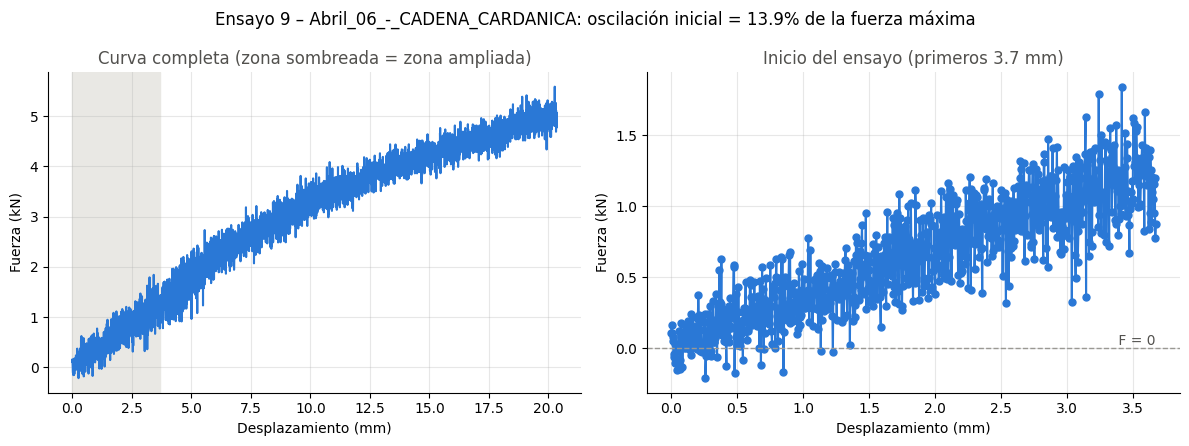

In [28]:
# 5.9 GRÁFICA DEL INICIO DEL ENSAYO CON MAYOR OSCILACIÓN RELATIVA
cadena = diagnostico[diagnostico["Componente"] == "Cadena"]
ejemplo = cadena.loc[cadena["Oscilacion_vs_Fmax_pct"].idxmax()]
curva_ejemplo = curvas[curvas["ID_Ensayo"] == ejemplo["ID_Ensayo"]]
limite_zoom = max(1.0, 3 * ejemplo["Desplazamiento_Ultimo_Negativo_mm"])
inicio = curva_ejemplo[curva_ejemplo["Desplazamiento_mm"] <= limite_zoom]

COLOR_SERIE = "#2a78d6"
COLOR_TEXTO = "#52514e"
COLOR_REFERENCIA = "#9a9893"

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

ejes[0].plot(curva_ejemplo["Desplazamiento_mm"], curva_ejemplo["Fuerza_kN"], color=COLOR_SERIE, linewidth=1.5)
ejes[0].axvspan(0, limite_zoom, color="#e9e8e4", zorder=0)
ejes[0].set_title("Curva completa (zona sombreada = zona ampliada)", color=COLOR_TEXTO)

ejes[1].plot(inicio["Desplazamiento_mm"], inicio["Fuerza_kN"], color=COLOR_SERIE, linewidth=1.5,
             marker="o", markersize=5)
ejes[1].axhline(0, color=COLOR_REFERENCIA, linestyle="--", linewidth=1)
ejes[1].text(limite_zoom, 0, " F = 0", color=COLOR_TEXTO, va="bottom", ha="right")
ejes[1].set_title(f"Inicio del ensayo (primeros {limite_zoom:.1f} mm)", color=COLOR_TEXTO)

for eje in ejes:
    eje.set_xlabel("Desplazamiento (mm)")
    eje.set_ylabel("Fuerza (kN)")
    eje.grid(alpha=0.3)
    eje.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"Ensayo {int(ejemplo['ID_Ensayo'])} – {ejemplo['Campaña']}: "
             f"oscilación inicial = {ejemplo['Oscilacion_vs_Fmax_pct']:.1f}% de la fuerza máxima")
plt.tight_layout()
plt.show()

### 5.10 Decisión sobre los valores negativos

Se conservan todos los puntos del registro. Se agregan tres marcas:
- **Fuerza_Negativa:** punto con fuerza menor que 0.
- **Fase:** "Carga" hasta el punto de fuerza máxima y "Post_Fmax" después de ella.
- **Ruido_Alto:** ensayos cuya oscilación inicial supera el 10% de su fuerza máxima.

In [29]:
# 5.10 MARCAS DE FUERZA NEGATIVA, FASE DEL ENSAYO Y RUIDO ALTO
curvas["Fuerza_Negativa"] = curvas["Fuerza_kN"] < 0

# Fase: el índice de cada punto se compara con el índice del punto de fuerza máxima de su ensayo
idx_max = curvas.groupby("ID_Ensayo")["Fuerza_kN"].idxmax()
curvas["Fase"] = np.where(curvas.index <= curvas["ID_Ensayo"].map(idx_max), "Carga", "Post_Fmax")

# Ruido alto: oscilación inicial mayor al 10% de la fuerza máxima
resumen_equipo = resumen_equipo.merge(
    diagnostico[["ID_Ensayo", "Oscilacion_Inicial_kN", "Oscilacion_vs_Fmax_pct"]], on="ID_Ensayo"
)
resumen_equipo["Ruido_Alto"] = resumen_equipo["Oscilacion_vs_Fmax_pct"] > 10

print("PUNTOS POR FASE Y SIGNO DE LA FUERZA")
print(pd.crosstab(curvas["Fase"], curvas["Fuerza_Negativa"], margins=True, margins_name="Total").to_string())

print("\nENSAYOS CON RUIDO ALTO POR COMPONENTE")
print(resumen_equipo.merge(inventario_ensayos[["ID_Ensayo", "Componente"]], on="ID_Ensayo")
      .groupby("Componente")["Ruido_Alto"].agg(["sum", "count"]).to_string())

registrar_decision(
    "Fuerza_kN (valores negativos al inicio)",
    "157 de 158 ensayos tienen fuerzas negativas antes de la fuerza máxima (ruido de ~0,5 kN alrededor de cero)",
    "No se eliminaron; se marcaron con la columna Fuerza_Negativa",
    "Es ruido de la señal presente en todo el ensayo; eliminar solo los negativos sesgaría la fuerza hacia arriba y no cambia la fuerza máxima"
)
registrar_decision(
    "Fase del ensayo",
    "139 ensayos tienen fuerzas negativas después de la fuerza máxima (hasta -5 kN), cuando la pieza ya falló",
    "Se creó la columna Fase (Carga / Post_Fmax) sin eliminar puntos",
    "Permite analizar solo la zona de carga cuando sea necesario, conservando el registro completo"
)
registrar_decision(
    "Ruido_Alto",
    "En hebillas y pines el ruido es comparable a la fuerza máxima (45% a 83%)",
    "Se marcaron los ensayos con oscilación inicial mayor al 10% de su fuerza máxima",
    "Sus resultados deben interpretarse con precaución por su baja relación señal/ruido"
)
print(f"\nDecisiones registradas hasta ahora: {len(decisiones)}")

PUNTOS POR FASE Y SIGNO DE LA FUERZA
Fuerza_Negativa   False   True   Total
Fase                                  
Carga            498372   4151  502523
Post_Fmax         20669  14817   35486
Total            519041  18968  538009

ENSAYOS CON RUIDO ALTO POR COMPONENTE
            sum  count
Componente            
Cadena        6    142
Hebilla       2      2
Pin          12     12
Piñón         0      2

Decisiones registradas hasta ahora: 16


**Observación:** de los 18.968 puntos con fuerza negativa, 14.817 (78%) ocurren después de
la fuerza máxima, cuando la pieza ya falló. Durante la fase de carga solo el 0,8% de los
puntos son negativos. Se marcaron con ruido alto todos los pines (12), las 2 hebillas y
6 ensayos de cadena; sus resultados se interpretarán con precaución.

### Pregunta de análisis: ¿deben eliminarse automáticamente los valores negativos iniciales?

No. Se decidió conservarlos por las siguientes razones:

1. **Son ruido de la señal, no errores de medición.** La oscilación tiene un tamaño similar
   en todos los ensayos (mediana ≈ 0,5 kN) y se observa a lo largo de toda la curva; al inicio
   aparecen valores negativos solo porque la fuerza real todavía es cercana a cero.
2. **Se concentran al comienzo.** En la cadena, el último valor negativo antes de la fuerza
   máxima ocurre en una mediana de 0,21 mm, apenas el 1,5% del recorrido hasta la fuerza máxima.
3. **No afectan las variables de análisis.** La fuerza máxima y el desplazamiento en la
   fuerza máxima son iguales con o sin esos puntos.
4. **Eliminarlos introduciría un sesgo.** Si se quitan solo los negativos y se conservan las
   oscilaciones positivas del mismo tamaño, la fuerza inicial quedaría artificialmente alta,
   y además se crearían huecos en el registro.

Lo que sí es relevante es el tamaño del ruido respecto a la fuerza máxima: en la cadena es
pequeño (mediana 3,6%), pero en hebillas (83%) y pines (45%) es comparable a la señal, por lo
que esos ensayos se marcaron con Ruido_Alto. Los valores negativos posteriores a la fuerza
máxima (hasta -5 kN) ocurren cuando la pieza ya falló y se identifican con la columna Fase.

### 5.11 Comparación antes y después de la limpieza

In [30]:
# 5.11 COMPARACIÓN ANTES Y DESPUÉS DE LA LIMPIEZA
comparacion_resumen = pd.DataFrame({
    "Antes (resumen_equipo_crudo)": [
        resumen_equipo_crudo.shape[0],
        resumen_equipo_crudo.shape[1],
        resumen_equipo_crudo.select_dtypes("number").shape[1],
        int((resumen_equipo_crudo == "-.-").sum().sum())
    ],
    "Después (resumen_equipo)": [
        resumen_equipo.shape[0],
        resumen_equipo.shape[1],
        resumen_equipo.select_dtypes("number").shape[1],
        int((resumen_equipo.astype(str) == "-.-").sum().sum())
    ]
}, index=["Filas", "Columnas", "Columnas numéricas", "Códigos '-.-'"])

print("TABLA RESUMEN DEL EQUIPO")
print(comparacion_resumen.to_string())

print("\nREGISTRO EXPERIMENTAL")
print("Filas antes:", len(curvas_crudas), "| Filas después:", len(curvas), "(no se eliminó ningún punto)")
print("Columnas antes:", curvas_crudas.columns.tolist())
print("Columnas después:", curvas.columns.tolist())

bitacora = pd.DataFrame(decisiones)
print(f"\nBITÁCORA DE LIMPIEZA ({len(bitacora)} decisiones)")
display(bitacora)

TABLA RESUMEN DEL EQUIPO
                    Antes (resumen_equipo_crudo)  Después (resumen_equipo)
Filas                                        158                       158
Columnas                                      28                        21
Columnas numéricas                             2                        17
Códigos '-.-'                                704                         0

REGISTRO EXPERIMENTAL
Filas antes: 538009 | Filas después: 538009 (no se eliminó ningún punto)
Columnas antes: ['ID_Ensayo', 'Año', 'Campaña', 'Archivo', 'Tiempo_s', 'Fuerza_kN', 'Desplazamiento_mm']
Columnas después: ['ID_Ensayo', 'Año', 'Campaña', 'Archivo', 'Tiempo_s', 'Fuerza_kN', 'Desplazamiento_mm', 'Fuerza_Negativa', 'Fase']

BITÁCORA DE LIMPIEZA (16 decisiones)


,Variable,Problema detectado,Acción tomada,Justificación
0,Unidades,Se verificó si los archivos usan unidades dist...,"No se convirtió ninguna unidad: todos usan s, ...",Las 158 lecturas muestran las mismas unidades ...
1,Valores resumen (todas las columnas numéricas),Números escritos con coma decimal y espacios (...,Se eliminaron espacios y se reemplazó la coma ...,Python solo reconoce el punto como separador d...
2,"Valores resumen (Break_*, YP_*, YS1_*)",El equipo usa el símbolo '-.-' cuando no calcu...,Se reemplazó '-.-' por NaN,"Es un código de dato no disponible, no un valo..."
3,Geometría de la probeta,La misma medida aparece con nombre en inglés o...,"Se unieron en una sola columna: Espesor_mm, An...",Evita tener dos columnas para la misma variabl...
4,Nombres de columnas del resumen,"Nombres en inglés y sin unidad (Max_Force, YP_...",Se renombraron en español incluyendo la unidad...,Deja explícita la unidad de cada variable y fa...
5,Año / Fecha_Campaña,El año estaba como texto y la fecha solo apare...,Año se convirtió a entero y se creó Fecha_Camp...,Permite ordenar las campañas en el tiempo y us...
6,"Fórmula, Muestra, Cavidad",Contienen números pero representan categorías ...,Se mantuvieron como texto,Operarlos como números no tiene sentido y algu...
7,Condición / Patron,'HOMOLOGACION DE MATERIAL' y 'HOMOLOGACION MAT...,Se unificó la escritura y se creó la columna P...,Evita separar una misma condición en dos categ...
8,Forma,La forma aparece en inglés o español (Plate / ...,Se unificó como Placa o Cilindro,Es la misma categoría escrita en dos idiomas
9,Columnas de rotura (Rotura_*) y YS1_*,100% de valores faltantes: el equipo nunca reg...,Se eliminaron estas columnas de resumen_equipo,No contienen ningún dato utilizable; conservar...


**Observación sobre la limpieza:** la tabla de resultados del equipo pasó de 2 a 17 columnas
numéricas, se eliminaron los 704 códigos "-.-" y se redujo de 28 a 21 columnas al eliminar
columnas vacías y unificar la geometría. En el registro experimental no se eliminó ningún
punto (538.009 antes y después); en su lugar se agregaron marcas (Fuerza_Negativa y Fase)
que permiten filtrar los datos según el análisis. Las 16 decisiones quedan documentadas
en la bitácora.

## 6. Construcción de los DataFrames

Se construyen dos bases consolidadas:
- **datos_experimentales:** una fila por cada punto registrado, con la información del ensayo
  al que pertenece (año, campaña, componente, fórmula, muestra, cavidad, tiempo de proceso,
  condición) y las variables medidas (Tiempo_s, Fuerza_kN, Desplazamiento_mm).
- **resumen_ensayos:** una fila por ensayo, con su identificación, el número de observaciones,
  la fuerza máxima, el desplazamiento y el tiempo en que ocurre, y la media, mediana y
  desviación estándar de la fuerza.

Para no confundir los dos tiempos, el tiempo de procesamiento de la pieza se llama
Tiempo_Proceso_min y el tiempo del ensayo se llama Tiempo_s.

In [31]:
# 6.1 DATAFRAME 1: DATOS EXPERIMENTALES
columnas_ensayo = ["ID_Ensayo", "Fecha_Campaña", "Componente", "Referencia", "Tipo_Ensayo",
                   "Fórmula", "Muestra", "Contramuestra", "Patron", "Cavidad", "Tiempo_min", "Condición"]

datos_experimentales = curvas.merge(
    inventario_ensayos[columnas_ensayo].rename(columns={"Tiempo_min": "Tiempo_Proceso_min"}),
    on="ID_Ensayo",
    how="left",
    validate="m:1"     # cada punto pertenece a un solo ensayo
)

orden_datos = ["ID_Ensayo", "Año", "Fecha_Campaña", "Campaña", "Archivo", "Componente", "Referencia",
               "Tipo_Ensayo", "Fórmula", "Muestra", "Contramuestra", "Patron", "Cavidad",
               "Tiempo_Proceso_min", "Condición", "Tiempo_s", "Fuerza_kN", "Desplazamiento_mm",
               "Fuerza_Negativa", "Fase"]
datos_experimentales = datos_experimentales[orden_datos]

print("DATAFRAME 1: DATOS EXPERIMENTALES")
print("Dimensiones:", datos_experimentales.shape)
print("Ensayos incluidos:", datos_experimentales["ID_Ensayo"].nunique())
print("Filas sin información del ensayo:", datos_experimentales["Tipo_Ensayo"].isna().sum())
display(datos_experimentales.head())

DATAFRAME 1: DATOS EXPERIMENTALES
Dimensiones: (538009, 20)
Ensayos incluidos: 158
Filas sin información del ensayo: 0


,ID_Ensayo,Año,Fecha_Campaña,Campaña,Archivo,Componente,Referencia,Tipo_Ensayo,Fórmula,Muestra,Contramuestra,Patron,Cavidad,Tiempo_Proceso_min,Condición,Tiempo_s,Fuerza_kN,Desplazamiento_mm,Fuerza_Negativa,Fase
0,1,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_1391_-_MUESTRA_1.txt,Cadena,1400,Tensión,NaN,1,False,False,NaN,NaN,1391,0.00,-0.068750,0.000,True,Carga
1,1,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_1391_-_MUESTRA_1.txt,Cadena,1400,Tensión,NaN,1,False,False,NaN,NaN,1391,0.05,0.025000,0.002,False,Carga
2,1,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_1391_-_MUESTRA_1.txt,Cadena,1400,Tensión,NaN,1,False,False,NaN,NaN,1391,0.10,-0.031250,0.005,True,Carga
3,1,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_1391_-_MUESTRA_1.txt,Cadena,1400,Tensión,NaN,1,False,False,NaN,NaN,1391,0.15,-0.125000,0.009,True,Carga
4,1,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_1391_-_MUESTRA_1.txt,Cadena,1400,Tensión,NaN,1,False,False,NaN,NaN,1391,0.20,-0.040625,0.014,True,Carga


**Nota sobre el resumen por ensayo:** la fuerza máxima, su desplazamiento y su tiempo se
obtienen del punto de fuerza máxima de cada curva (en la sección 5.7 se verificó que
coincide con el valor reportado por el equipo). La media, mediana y desviación estándar se
calculan sobre el registro completo; como dependen de cuánto duró cada ensayo y de la parte
posterior a la falla, se usan como descripción del registro y no como variable principal de
comparación. Para comparar ensayos se usarán la fuerza máxima y el desplazamiento en la
fuerza máxima.

In [32]:
# 6.2 DATAFRAME 2: RESUMEN POR ENSAYO
estadisticas = datos_experimentales.groupby("ID_Ensayo").agg(
    N_Observaciones=("Fuerza_kN", "size"),
    Duracion_s=("Tiempo_s", "max"),
    Fuerza_Media_kN=("Fuerza_kN", "mean"),
    Fuerza_Mediana_kN=("Fuerza_kN", "median"),
    Fuerza_Desv_kN=("Fuerza_kN", "std")
).reset_index()

# Punto de fuerza máxima de cada ensayo
idx_max = datos_experimentales.groupby("ID_Ensayo")["Fuerza_kN"].idxmax()
punto_max = datos_experimentales.loc[idx_max, ["ID_Ensayo", "Fuerza_kN", "Desplazamiento_mm", "Tiempo_s"]].rename(
    columns={
        "Fuerza_kN": "Fuerza_Max_kN",
        "Desplazamiento_mm": "Desplazamiento_en_Fmax_mm",
        "Tiempo_s": "Tiempo_en_Fmax_s"
    }
)

# Valores del equipo que siguen siendo útiles después de la limpieza
columnas_equipo = ["ID_Ensayo", "Fuerza_YP_kN", "Desplazamiento_YP_mm", "Esfuerzo_Max_Nmm2",
                   "Geometria_Real", "Oscilacion_vs_Fmax_pct", "Ruido_Alto"]

resumen_ensayos = (
    inventario_ensayos[["ID_Ensayo", "Año", "Campaña", "Archivo"] + columnas_ensayo[1:]]
    .rename(columns={"Tiempo_min": "Tiempo_Proceso_min"})
    .merge(estadisticas, on="ID_Ensayo", validate="1:1")
    .merge(punto_max, on="ID_Ensayo", validate="1:1")
    .merge(resumen_equipo[columnas_equipo], on="ID_Ensayo", validate="1:1")
)

orden_resumen = ["ID_Ensayo", "Año", "Fecha_Campaña", "Campaña", "Archivo", "Componente", "Referencia",
                 "Tipo_Ensayo", "Fórmula", "Muestra", "Contramuestra", "Patron", "Cavidad",
                 "Tiempo_Proceso_min", "Condición", "N_Observaciones", "Duracion_s",
                 "Fuerza_Max_kN", "Desplazamiento_en_Fmax_mm", "Tiempo_en_Fmax_s",
                 "Fuerza_Media_kN", "Fuerza_Mediana_kN", "Fuerza_Desv_kN",
                 "Fuerza_YP_kN", "Desplazamiento_YP_mm", "Esfuerzo_Max_Nmm2",
                 "Geometria_Real", "Oscilacion_vs_Fmax_pct", "Ruido_Alto"]
resumen_ensayos = resumen_ensayos[orden_resumen]

print("DATAFRAME 2: RESUMEN POR ENSAYO")
print("Dimensiones:", resumen_ensayos.shape)
print("Ensayos únicos:", resumen_ensayos["ID_Ensayo"].nunique())

faltantes_resumen = resumen_ensayos.isnull().sum()
print("\nCOLUMNAS CON VALORES FALTANTES")
print(faltantes_resumen[faltantes_resumen > 0].to_string())

display(resumen_ensayos.head())

DATAFRAME 2: RESUMEN POR ENSAYO
Dimensiones: (158, 29)
Ensayos únicos: 158

COLUMNAS CON VALORES FALTANTES
Referencia                2
Fórmula                 122
Muestra                   1
Cavidad                  44
Tiempo_Proceso_min       97
Condición                42
Fuerza_YP_kN             11
Desplazamiento_YP_mm     11
Esfuerzo_Max_Nmm2       144


,ID_Ensayo,Año,Fecha_Campaña,Campaña,Archivo,Componente,Referencia,Tipo_Ensayo,Fórmula,Muestra,Contramuestra,Patron,Cavidad,Tiempo_Proceso_min,Condición,N_Observaciones,Duracion_s,Fuerza_Max_kN,Desplazamiento_en_Fmax_mm,Tiempo_en_Fmax_s,Fuerza_Media_kN,Fuerza_Mediana_kN,Fuerza_Desv_kN,Fuerza_YP_kN,Desplazamiento_YP_mm,Esfuerzo_Max_Nmm2,Geometria_Real,Oscilacion_vs_Fmax_pct,Ruido_Alto
0,1,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_1391_-_MUESTRA_1.txt,Cadena,1400,Tensión,NaN,1,False,False,NaN,NaN,1391,3049,152.40,11.15000,12.326,147.95,6.277965,6.75000,3.265979,1.18750,0.551,NaN,False,3.755605,False
1,2,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_1391_-_MUESTRA_2.txt,Cadena,1400,Tensión,NaN,2,False,False,NaN,NaN,1391,2992,149.55,11.04375,12.261,147.20,6.405952,6.86875,3.200692,1.20938,0.494,NaN,False,2.801358,False
2,3,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_HEBILLA_MOLDE_ANTERIOR_-_MUESTRA_8.txt,Hebilla,NaN,Tensión,NaN,8,False,False,NaN,NaN,MOLDE ANTERIOR,2763,138.10,0.85000,13.740,82.50,0.142405,0.13125,0.158664,NaN,NaN,1.30769,True,72.058824,True
3,4,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_HEBILLA_MOLDE_NUEVO_-_MUESTRA_9.txt,Hebilla,NaN,Tensión,NaN,9,False,False,NaN,NaN,MOLDE NUEVO,2984,149.15,0.75625,17.471,104.90,0.175110,0.15625,0.156999,NaN,NaN,1.16346,True,93.388430,True
4,5,2022,2022-04-06,Abril_06_-_CADENA_CARDANICA,PLADESAN_LOTE_ACTUAL_-_MUESTRA_3.txt,Cadena,1400,Tensión,NaN,3,False,False,NaN,NaN,LOTE ACTUAL,4793,239.60,12.61563,19.744,237.00,7.572734,8.33750,3.429071,1.24063,0.548,NaN,False,3.591775,False


### 6.3 Almacenamiento de las bases

Las tablas finales se guardan en data/processed para documentar el resultado de la limpieza
y la transformación.

In [33]:
# 6.3 ALMACENAMIENTO DE LAS BASES CONSOLIDADAS
carpeta_procesados = Path("data/processed")
carpeta_procesados.mkdir(parents=True, exist_ok=True)

tablas = {
    "datos_experimentales.csv": datos_experimentales,
    "resumen_ensayos.csv": resumen_ensayos,
    "inventario_ensayos.csv": inventario_ensayos,
    "bitacora_limpieza.csv": bitacora
}

print("ARCHIVOS GUARDADOS")
for nombre_archivo, tabla in tablas.items():
    ruta_salida = carpeta_procesados / nombre_archivo
    tabla.to_csv(ruta_salida, index=False)
    print(f"{ruta_salida}  ({ruta_salida.stat().st_size / 1e6:.1f} MB, {len(tabla):,} filas)")

ARCHIVOS GUARDADOS
data/processed/datos_experimentales.csv  (103.7 MB, 538,009 filas)
data/processed/resumen_ensayos.csv  (0.0 MB, 158 filas)
data/processed/inventario_ensayos.csv  (0.0 MB, 158 filas)
data/processed/bitacora_limpieza.csv  (0.0 MB, 16 filas)


**Observación sobre las bases consolidadas:** datos_experimentales contiene 538.009
observaciones de los 158 ensayos (20 columnas), todas asociadas a su ensayo de origen.
resumen_ensayos contiene una fila por ensayo (29 columnas); sus valores faltantes
corresponden a variables que no aplican en algunas campañas o que el equipo no calculó,
como se explicó en la limpieza.

En los ensayos de cadena la media de la fuerza es cercana a la mitad de la fuerza máxima,
porque la fuerza aumenta de forma progresiva durante el ensayo. Por esto la media describe
el registro, pero la variable que representa la resistencia de la pieza es la fuerza máxima.

Las tablas se guardan en data/processed. En Colab estos archivos son temporales, pero se
vuelven a generar al ejecutar el notebook completo.

## 7. Análisis de 2022 – Caso de estudio: 4 de octubre de 2022

Se analizan los ensayos de tensión de la cadena 1400 de la campaña del 4 de octubre de 2022
para las Fórmulas 1, 2 y 3. Se excluyen los ensayos de compresión del pin y los ensayos
del piñón, porque corresponden a otros componentes o tipos de prueba. La selección se
hace con filtros sobre resumen_ensayos, sin escribir nombres de archivos.

In [34]:
# 7.1 SELECCIÓN DE LOS ENSAYOS Y MUESTRAS POR FÓRMULA
FECHA_CASO_2022 = pd.Timestamp("2022-10-04")
campana_oct = resumen_ensayos[resumen_ensayos["Fecha_Campaña"] == FECHA_CASO_2022]

print("ENSAYOS DE LA CAMPAÑA DEL 4 DE OCTUBRE DE 2022")
print(campana_oct.groupby(["Componente", "Tipo_Ensayo"]).size().to_string())

caso_2022 = campana_oct[
    (campana_oct["Componente"] == "Cadena") &
    (campana_oct["Tipo_Ensayo"] == "Tensión") &
    (campana_oct["Fórmula"].notna())
].copy()

caso_2022["Rol"] = np.where(caso_2022["Contramuestra"], "Contramuestra", "Muestra")
caso_2022 = caso_2022.sort_values(["Fórmula", "Rol", "Muestra"])

print("\nENSAYOS SELECCIONADOS:", len(caso_2022))
print(caso_2022[["ID_Ensayo", "Archivo", "Fórmula", "Muestra", "Rol"]].to_string(index=False))

print("\nMUESTRAS POR FÓRMULA")
print(pd.crosstab(caso_2022["Fórmula"], caso_2022["Rol"], margins=True, margins_name="Total").to_string())

ENSAYOS DE LA CAMPAÑA DEL 4 DE OCTUBRE DE 2022
Componente  Tipo_Ensayo
Cadena      Tensión        7
Pin         Compresión     7
Piñón       Tensión        2

ENSAYOS SELECCIONADOS: 7
 ID_Ensayo                                    Archivo Fórmula Muestra           Rol
        19 FORMULA_1._MUESTRA_1.1_-_CONTRAMUESTRA.txt       1     1.1 Contramuestra
        20                   FORMULA_1._MUESTRA_1.txt       1       1       Muestra
        21 FORMULA_2._MUESTRA_2.1_-_CONTRAMUESTRA.txt       2     2.1 Contramuestra
        22                   FORMULA_2._MUESTRA_2.txt       2       2       Muestra
        23                  FORMULA_2._MUESTRA_2B.txt       2      2B       Muestra
        24 FORMULA_3._MUESTRA_3.1_-_CONTRAMUESTRA.txt       3     3.1 Contramuestra
        25                   FORMULA_3._MUESTRA_3.txt       3       3       Muestra

MUESTRAS POR FÓRMULA
Rol      Contramuestra  Muestra  Total
Fórmula                               
1                    1        1      2
2    

**Observación:** la campaña del 4 de octubre de 2022 tiene 16 ensayos, de los cuales 7
corresponden a tensión de la cadena con fórmula identificada. Se excluyen 7 ensayos de
compresión del pin y 2 de tensión del piñón. La Fórmula 1 tiene 2 ensayos (muestra y
contramuestra), la Fórmula 2 tiene 3 (muestras 2 y 2B y contramuestra 2.1) y la Fórmula 3
tiene 2 (muestra y contramuestra).

### 7.2 Fuerza máxima por ensayo y comparación muestra – contramuestra

Además de la fuerza máxima registrada, se calcula una fuerza máxima suavizada (máximo de la
media móvil centrada de 21 puntos, equivalente a 1 s de ensayo). La fuerza registrada tiene
un ruido de aproximadamente ±0,5 kN, por lo que el valor máximo puntual incluye parte de ese
ruido. La versión suavizada sirve para verificar si las diferencias se mantienen.

In [35]:
# 7.2 FUERZA MÁXIMA POR ENSAYO Y MUESTRA VS CONTRAMUESTRA
def fuerza_max_suavizada(id_ensayo, ventana=21):
    """Máximo de la media móvil centrada de la fuerza (21 puntos = 1 s)."""
    fuerza = datos_experimentales.loc[datos_experimentales["ID_Ensayo"] == id_ensayo, "Fuerza_kN"]
    return fuerza.rolling(ventana, center=True).mean().max()

caso_2022["Fuerza_Max_Suavizada_kN"] = caso_2022["ID_Ensayo"].apply(fuerza_max_suavizada)

print("FUERZA MÁXIMA POR ENSAYO")
print(caso_2022[["Fórmula", "Muestra", "Rol", "Fuerza_Max_kN", "Fuerza_Max_Suavizada_kN",
                 "Desplazamiento_en_Fmax_mm", "Tiempo_en_Fmax_s", "Ruido_Alto"]]
      .round(3).to_string(index=False))

comparacion_mc = caso_2022.pivot_table(index="Fórmula", columns="Rol",
                                       values="Fuerza_Max_kN", aggfunc="mean")
comparacion_mc["N_Muestras"] = caso_2022[caso_2022["Rol"] == "Muestra"].groupby("Fórmula").size()
comparacion_mc["Diferencia_kN"] = comparacion_mc["Contramuestra"] - comparacion_mc["Muestra"]
comparacion_mc["Diferencia_pct"] = comparacion_mc["Diferencia_kN"] / comparacion_mc["Muestra"] * 100

print("\nMUESTRA VS CONTRAMUESTRA (fuerza máxima en kN; si hay dos muestras se usa su promedio)")
print(comparacion_mc.round(3).to_string())

FUERZA MÁXIMA POR ENSAYO
Fórmula Muestra           Rol  Fuerza_Max_kN  Fuerza_Max_Suavizada_kN  Desplazamiento_en_Fmax_mm  Tiempo_en_Fmax_s  Ruido_Alto
      1     1.1 Contramuestra         11.622                   11.377                      4.494             54.00       False
      1       1       Muestra          8.981                    8.316                      3.647             43.80       False
      2     2.1 Contramuestra         13.016                   12.566                      7.008             84.15       False
      2       2       Muestra         16.938                   16.551                      8.653            103.90       False
      2      2B       Muestra         13.391                   13.087                      7.645             91.80       False
      3     3.1 Contramuestra         14.759                   14.406                     17.062            204.80       False
      3       3       Muestra         16.081                   15.665                 

**Observación:** la diferencia entre muestra y contramuestra no tiene una dirección
constante: en la Fórmula 1 la contramuestra supera a la muestra en 2,64 kN (29%), mientras
que en las Fórmulas 2 y 3 la contramuestra es menor (-14% y -8%). La fuerza máxima
suavizada es entre 0,25 y 0,67 kN menor que la registrada, lo que confirma que el valor
puntual incluye parte del ruido, pero el orden entre los ensayos no cambia.

### 7.3 Estadísticos descriptivos por fórmula

Con 2 o 3 ensayos por fórmula, la desviación estándar es poco estable, por lo que también se
reportan el mínimo, el máximo y el rango.

In [36]:
# 7.3 ESTADÍSTICOS DESCRIPTIVOS POR FÓRMULA
estadisticos_2022 = caso_2022.groupby("Fórmula").agg(
    N=("Fuerza_Max_kN", "size"),
    Fmax_Media_kN=("Fuerza_Max_kN", "mean"),
    Fmax_Mediana_kN=("Fuerza_Max_kN", "median"),
    Fmax_Desv_kN=("Fuerza_Max_kN", "std"),
    Fmax_Min_kN=("Fuerza_Max_kN", "min"),
    Fmax_Max_kN=("Fuerza_Max_kN", "max"),
    Fmax_Suavizada_Media_kN=("Fuerza_Max_Suavizada_kN", "mean"),
    Desp_Fmax_Media_mm=("Desplazamiento_en_Fmax_mm", "mean"),
    Desp_Fmax_Min_mm=("Desplazamiento_en_Fmax_mm", "min"),
    Desp_Fmax_Max_mm=("Desplazamiento_en_Fmax_mm", "max")
)
estadisticos_2022["Fmax_Rango_kN"] = estadisticos_2022["Fmax_Max_kN"] - estadisticos_2022["Fmax_Min_kN"]
estadisticos_2022["Fmax_CV_pct"] = estadisticos_2022["Fmax_Desv_kN"] / estadisticos_2022["Fmax_Media_kN"] * 100

print("ESTADÍSTICOS POR FÓRMULA")
print(estadisticos_2022.round(3).T.to_string())

ESTADÍSTICOS POR FÓRMULA
Fórmula                       1       2       3
N                         2.000   3.000   2.000
Fmax_Media_kN            10.302  14.448  15.420
Fmax_Mediana_kN          10.302  13.391  15.420
Fmax_Desv_kN              1.867   2.164   0.935
Fmax_Min_kN               8.981  13.016  14.759
Fmax_Max_kN              11.622  16.938  16.081
Fmax_Suavizada_Media_kN   9.847  14.068  15.036
Desp_Fmax_Media_mm        4.070   7.769  17.476
Desp_Fmax_Min_mm          3.647   7.008  17.062
Desp_Fmax_Max_mm          4.494   8.653  17.891
Fmax_Rango_kN             2.641   3.922   1.322
Fmax_CV_pct              18.125  14.979   6.062


**Observación:** la Fórmula 3 tiene la mayor fuerza máxima promedio (15,42 kN) y la menor
variabilidad (CV 6,1%); la Fórmula 1 tiene el menor promedio (10,30 kN). El desplazamiento
en la fuerza máxima es la variable que más separa las fórmulas: 3,6–4,5 mm en la
Fórmula 1, 7,0–8,7 mm en la Fórmula 2 y 17,1–17,9 mm en la Fórmula 3, sin superposición
entre ellas. En cambio, los rangos de fuerza máxima de las Fórmulas 2 y 3 se superponen.

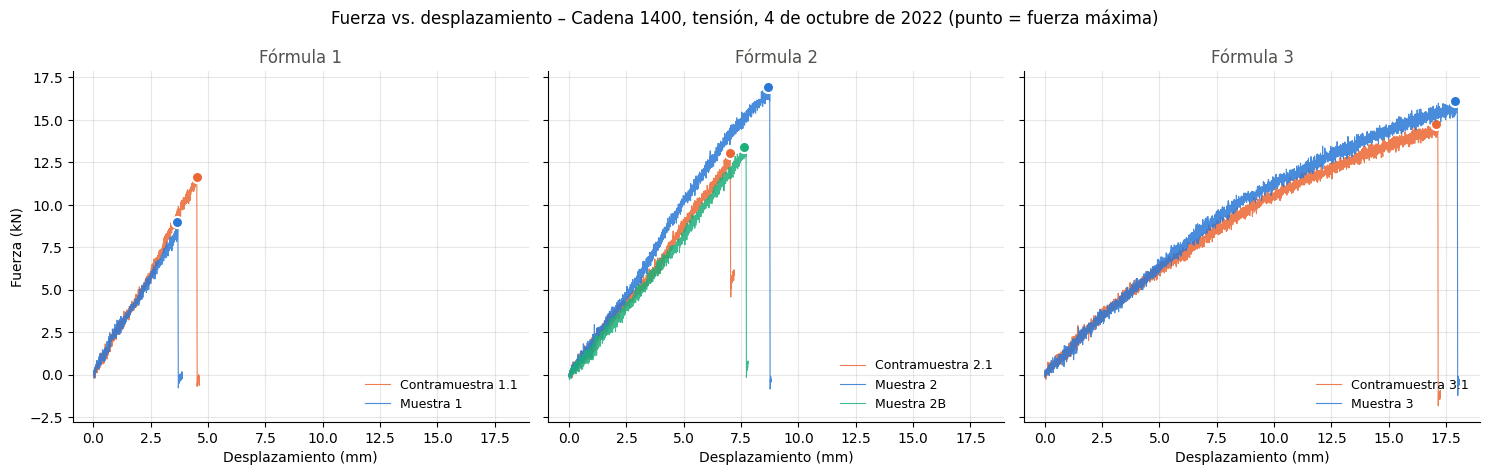

In [37]:
# 7.4 GRÁFICA FUERZA VS DESPLAZAMIENTO
COLORES_MUESTRA = ["#2a78d6", "#1baf7a"]   # primera y segunda muestra de cada fórmula
COLOR_CONTRAMUESTRA = "#eb6834"
COLOR_TEXTO = "#52514e"

formulas = sorted(caso_2022["Fórmula"].unique())
fig, ejes = plt.subplots(1, len(formulas), figsize=(15, 4.8), sharex=True, sharey=True)

for eje, formula in zip(ejes, formulas):
    ensayos_formula = caso_2022[caso_2022["Fórmula"] == formula]
    numero_muestra = 0
    for _, ensayo in ensayos_formula.iterrows():
        curva = datos_experimentales[datos_experimentales["ID_Ensayo"] == ensayo["ID_Ensayo"]]
        if ensayo["Rol"] == "Contramuestra":
            color = COLOR_CONTRAMUESTRA
        else:
            color = COLORES_MUESTRA[numero_muestra]
            numero_muestra += 1
        eje.plot(curva["Desplazamiento_mm"], curva["Fuerza_kN"], color=color, linewidth=0.8,
                 alpha=0.85, label=f"{ensayo['Rol']} {ensayo['Muestra']}")
        eje.plot(ensayo["Desplazamiento_en_Fmax_mm"], ensayo["Fuerza_Max_kN"], "o", color=color,
                 markersize=8, markeredgecolor="white", markeredgewidth=1.5)

    eje.set_title(f"Fórmula {formula}", color=COLOR_TEXTO)
    eje.set_xlabel("Desplazamiento (mm)")
    eje.grid(alpha=0.3)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(frameon=False, fontsize=9, loc="lower right")

ejes[0].set_ylabel("Fuerza (kN)")
fig.suptitle("Fuerza vs. desplazamiento – Cadena 1400, tensión, 4 de octubre de 2022 (punto = fuerza máxima)")
plt.tight_layout()
plt.show()

**Observación:** dentro de cada fórmula las curvas siguen prácticamente la misma
trayectoria durante la carga; la diferencia principal es el desplazamiento al que ocurre
la falla, después de la cual la fuerza cae bruscamente a cero. En la Fórmula 1, la muestra 1
falla a 3,6 mm y la contramuestra a 4,5 mm, lo que explica su diferencia de fuerza máxima.
En las Fórmulas 1 y 2 la fuerza aumenta de forma casi lineal hasta la falla, mientras que
en la Fórmula 3 la curva se va aplanando y la pieza alcanza un desplazamiento cuatro veces
mayor que en la Fórmula 1. En la Fórmula 2, la muestra 2 presenta una pendiente algo mayor
que las otras dos, cuyas curvas son casi iguales.

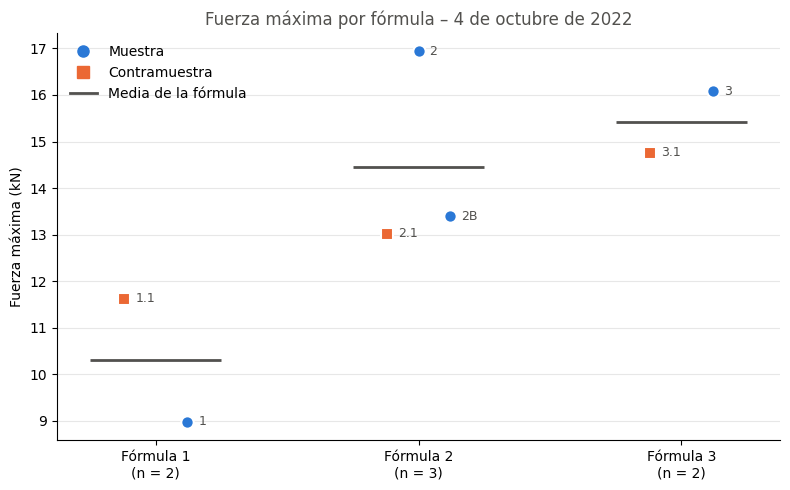

In [38]:
# 7.5 COMPARACIÓN DE LA FUERZA MÁXIMA ENTRE FÓRMULAS
from matplotlib.lines import Line2D

fig, eje = plt.subplots(figsize=(8, 5))

for i, formula in enumerate(formulas):
    ensayos_formula = caso_2022[caso_2022["Fórmula"] == formula]
    desplazamientos_x = np.linspace(-0.12, 0.12, len(ensayos_formula))   # separa puntos cercanos
    for dx, (_, ensayo) in zip(desplazamientos_x, ensayos_formula.iterrows()):
        es_contramuestra = ensayo["Rol"] == "Contramuestra"
        eje.scatter(i + dx, ensayo["Fuerza_Max_kN"], s=80,
                    marker="s" if es_contramuestra else "o",
                    color=COLOR_CONTRAMUESTRA if es_contramuestra else COLORES_MUESTRA[0],
                    edgecolor="white", linewidth=1.5, zorder=3)
        eje.annotate(ensayo["Muestra"], (i + dx, ensayo["Fuerza_Max_kN"]), xytext=(8, 0),
                     textcoords="offset points", va="center", fontsize=9, color=COLOR_TEXTO)
    eje.hlines(ensayos_formula["Fuerza_Max_kN"].mean(), i - 0.25, i + 0.25,
               color=COLOR_TEXTO, linewidth=2, zorder=2)

eje.set_xticks(range(len(formulas)))
eje.set_xticklabels([f"Fórmula {f}\n(n = {(caso_2022['Fórmula'] == f).sum()})" for f in formulas])
eje.set_ylabel("Fuerza máxima (kN)")
eje.set_title("Fuerza máxima por fórmula – 4 de octubre de 2022", color=COLOR_TEXTO)
eje.grid(axis="y", alpha=0.3)
eje.spines[["top", "right"]].set_visible(False)
eje.legend(handles=[
    Line2D([], [], marker="o", linestyle="", color=COLORES_MUESTRA[0], markersize=8, label="Muestra"),
    Line2D([], [], marker="s", linestyle="", color=COLOR_CONTRAMUESTRA, markersize=8, label="Contramuestra"),
    Line2D([], [], color=COLOR_TEXTO, linewidth=2, label="Media de la fórmula")
], frameon=False, loc="best")
plt.tight_layout()
plt.show()

**Observación:** se usa un gráfico de puntos porque con 2 o 3 ensayos por fórmula un
diagrama de caja no es representativo y un gráfico de barras de promedios ocultaría la
cantidad de datos y su dispersión. La gráfica muestra que todos los valores de la
Fórmula 1 están por debajo de los de las Fórmulas 2 y 3, mientras que las Fórmulas 2 y 3
se superponen: el valor más alto es de la Fórmula 2, pero sus otras dos muestras están por
debajo de ambas muestras de la Fórmula 3.

### Preguntas de análisis – Caso 2022

**1. ¿Cuál fórmula produjo el mayor valor individual de fuerza máxima?**
La Fórmula 2, con la muestra 2: 16,94 kN (16,55 kN con la fuerza suavizada).

**2. ¿Es suficiente para afirmar que esa fórmula es superior?**
No. Es un solo valor de un solo ensayo. Las otras dos muestras de la Fórmula 2 alcanzaron
13,02 y 13,39 kN, por debajo de las dos muestras de la Fórmula 3 (14,76 y 16,08 kN). Si se
usa la media o la mediana, la Fórmula 3 queda por encima (media 15,42 kN frente a 14,45 kN;
mediana 15,42 frente a 13,39 kN), y sin la muestra 2 la media de la Fórmula 2 bajaría a
13,20 kN. Además, la Fórmula 3 alcanza su fuerza máxima con un desplazamiento mucho mayor
(≈17,5 mm frente a ≈7,8 mm). La "mejor" fórmula depende del criterio, y un valor
individual no representa el comportamiento de la formulación.

**3. ¿Qué diferencias hay entre muestras de una misma fórmula?**
Durante la carga, las curvas de una misma fórmula son casi iguales; la diferencia está en el
desplazamiento al que ocurre la falla, y eso determina la fuerza máxima alcanzada. En la
Fórmula 1 la muestra falla a 3,6 mm (8,98 kN) y la contramuestra a 4,5 mm (11,62 kN), una
diferencia del 29%. En la Fórmula 2, las muestras 2B y 2.1 son muy parecidas (13,39 y 13,02
kN), mientras que la muestra 2 tiene una pendiente algo mayor y falla más tarde (16,94 kN).
La Fórmula 3 es la más homogénea (diferencia de 1,32 kN, 8%). La contramuestra no es
sistemáticamente mayor ni menor que la muestra.

**4. ¿Cuál fórmula presenta mayor variabilidad?**
Depende de la medida. En términos absolutos, la Fórmula 2 (rango 3,92 kN, desviación
2,16 kN), influida por la muestra 2. En términos relativos, la Fórmula 1 (CV 18,1%), porque
su fuerza media es menor. La Fórmula 3 es la menos variable en ambas medidas (rango 1,32 kN,
CV 6,1%). Con solo 2 o 3 valores por fórmula, la desviación estándar es poco confiable,
por lo que el rango es una medida más honesta.

**5. ¿Qué limitaciones tendría una conclusión general?**
- Solo hay 7 ensayos (2, 3 y 2 por fórmula): un único ensayo atípico cambia la media y el
  orden entre fórmulas, y no es posible estimar de forma confiable la variabilidad ni aplicar
  pruebas estadísticas.
- Todos los ensayos son de una sola campaña (un solo día y, probablemente, un solo lote), por
  lo que no se puede generalizar a otras producciones.
- La fuerza tiene un ruido de ≈0,5 kN, del mismo orden que algunas diferencias observadas.
- No se registró la cavidad ni otras condiciones del proceso, y no se sabe qué distingue
  exactamente a la contramuestra ni a la muestra 2B.
- La geometría registrada es de relleno, por lo que no se puede calcular el esfuerzo real, y
  el desplazamiento corresponde al recorrido de la máquina, no al alargamiento medido de la pieza.

Con estos datos solo se pueden plantear tendencias: la Fórmula 1 alcanzó las fuerzas
máximas más bajas, la Fórmula 3 fue la más homogénea y la que soportó mayor desplazamiento
antes de fallar, y la diferencia de fuerza máxima entre las Fórmulas 2 y 3 no puede
establecerse con seguridad. Confirmarlo requeriría más ensayos por fórmula.

## 8. Análisis de 2024 – Caso de estudio: 26 de abril de 2024

Se analizan los ensayos REGULAR ESTANDAR de la cadena 1400: 2 fórmulas × 2 cavidades ×
5 tiempos de proceso (0, 15, 30, 45 y 60 min). Se excluyen los 4 ensayos
"REGULAR ESTANDAR SIN PLA 1339", que corresponden a otra condición y no tienen tiempo de
proceso. Como existe un solo ensayo por combinación, los resultados se presentan como
tendencias observadas y no como diferencias demostradas estadísticamente.

In [39]:
# 8.1 SELECCIÓN DE LOS ENSAYOS Y TABLA RESUMEN
FECHA_CASO_2024 = pd.Timestamp("2024-04-26")
campana_abr = resumen_ensayos[resumen_ensayos["Fecha_Campaña"] == FECHA_CASO_2024]

print("CONDICIONES DE LA CAMPAÑA DEL 26 DE ABRIL DE 2024")
print(campana_abr.groupby("Condición", dropna=False).size().to_string())

caso_2024 = campana_abr[
    (campana_abr["Condición"] == "REGULAR ESTANDAR") &
    (campana_abr["Fórmula"].notna()) &
    (campana_abr["Tiempo_Proceso_min"].notna())
].copy()
caso_2024["Tiempo_Proceso_min"] = caso_2024["Tiempo_Proceso_min"].astype(int)
caso_2024["Fuerza_Max_Suavizada_kN"] = caso_2024["ID_Ensayo"].apply(fuerza_max_suavizada)
caso_2024 = caso_2024.sort_values(["Fórmula", "Cavidad", "Tiempo_Proceso_min"])

tabla_2024 = caso_2024[["Fórmula", "Cavidad", "Tiempo_Proceso_min", "Muestra", "Fuerza_Max_kN",
                        "Fuerza_Max_Suavizada_kN", "Desplazamiento_en_Fmax_mm", "Ruido_Alto"]]

print("\nTABLA RESUMEN:", len(tabla_2024), "ensayos")
print(tabla_2024.round(3).to_string(index=False))

CONDICIONES DE LA CAMPAÑA DEL 26 DE ABRIL DE 2024
Condición
REGULAR ESTANDAR                 20
REGULAR ESTANDAR SIN PLA 1339     4

TABLA RESUMEN: 20 ensayos
Fórmula Cavidad  Tiempo_Proceso_min Muestra  Fuerza_Max_kN  Fuerza_Max_Suavizada_kN  Desplazamiento_en_Fmax_mm  Ruido_Alto
      1       1                   0       5         14.078                   13.655                     15.421       False
      1       1                  15       7         15.962                   15.717                     16.096       False
      1       1                  30       9         13.812                   13.586                     14.089       False
      1       1                  45      11         15.488                   15.184                     15.872       False
      1       1                  60      13         12.650                   12.433                     11.194       False
      1       2                   0       6         15.197                   14.683                    

In [40]:
# 8.2 VERIFICACIÓN DEL DISEÑO FÓRMULA – CAVIDAD – TIEMPO
verificacion = pd.crosstab([caso_2024["Fórmula"], caso_2024["Cavidad"]], caso_2024["Tiempo_Proceso_min"])

print("ENSAYOS POR FÓRMULA, CAVIDAD Y TIEMPO")
print(verificacion.to_string())

esperadas = (caso_2024["Fórmula"].nunique() * caso_2024["Cavidad"].nunique()
             * caso_2024["Tiempo_Proceso_min"].nunique())
print("\nCombinaciones esperadas:", esperadas, "| Ensayos encontrados:", len(caso_2024))
print("Combinaciones con más de un ensayo:", int((verificacion > 1).sum().sum()))
print("Combinaciones sin ensayo:", int((verificacion == 0).sum().sum()))

ENSAYOS POR FÓRMULA, CAVIDAD Y TIEMPO
Tiempo_Proceso_min  0   15  30  45  60
Fórmula Cavidad                       
1       1            1   1   1   1   1
        2            1   1   1   1   1
2       1            1   1   1   1   1
        2            1   1   1   1   1

Combinaciones esperadas: 20 | Ensayos encontrados: 20
Combinaciones con más de un ensayo: 0
Combinaciones sin ensayo: 0


**Observación:** se identificaron los 20 ensayos REGULAR ESTANDAR esperados: 2 fórmulas ×
2 cavidades × 5 tiempos, con exactamente un ensayo por combinación y ninguno marcado con
ruido alto. Los 4 ensayos "REGULAR ESTANDAR SIN PLA 1339" se excluyen del análisis principal.

### 8.3 Efecto del tiempo de proceso

Para describir la tendencia se ajusta una recta a la fuerza máxima en función del tiempo y
se reporta su pendiente (kN por hora) y su R². Con 5 puntos por combinación, la pendiente
se usa como descripción y no como prueba de que exista un efecto.

In [41]:
# 8.3 FUERZA MÁXIMA POR TIEMPO Y TENDENCIA
pivote_fmax = caso_2024.pivot_table(index="Tiempo_Proceso_min", columns=["Fórmula", "Cavidad"],
                                    values="Fuerza_Max_kN")
pivote_desp = caso_2024.pivot_table(index="Tiempo_Proceso_min", columns=["Fórmula", "Cavidad"],
                                    values="Desplazamiento_en_Fmax_mm")

print("FUERZA MÁXIMA (kN) POR TIEMPO, FÓRMULA Y CAVIDAD")
print(pivote_fmax.round(2).to_string())
print("\nDESPLAZAMIENTO EN LA FUERZA MÁXIMA (mm)")
print(pivote_desp.round(2).to_string())

def tendencia(grupo, formula, cavidad):
    """Ajusta una recta Fuerza máxima vs Tiempo y resume el cambio entre 0 y 60 min."""
    grupo = grupo.sort_values("Tiempo_Proceso_min")
    x = grupo["Tiempo_Proceso_min"]
    y = grupo["Fuerza_Max_kN"]
    pendiente, _ = np.polyfit(x, y, 1)
    r = np.corrcoef(x, y)[0, 1]
    inicial = grupo[grupo["Tiempo_Proceso_min"] == x.min()]["Fuerza_Max_kN"].mean()
    final = grupo[grupo["Tiempo_Proceso_min"] == x.max()]["Fuerza_Max_kN"].mean()
    return {"Fórmula": formula, "Cavidad": cavidad, "N": len(grupo),
            "Fmax_0min_kN": inicial, "Fmax_60min_kN": final,
            "Cambio_0_a_60_kN": final - inicial,
            "Pendiente_kN_por_hora": pendiente * 60, "R2": r ** 2,
            "Rango_kN": y.max() - y.min()}

filas_tendencia = []
for (formula, cavidad), grupo in caso_2024.groupby(["Fórmula", "Cavidad"]):
    filas_tendencia.append(tendencia(grupo, formula, cavidad))
for formula, grupo in caso_2024.groupby("Fórmula"):
    filas_tendencia.append(tendencia(grupo, formula, "Ambas"))

tendencias_2024 = pd.DataFrame(filas_tendencia)
print("\nTENDENCIA DE LA FUERZA MÁXIMA ENTRE 0 Y 60 MIN")
print(tendencias_2024.round(3).to_string(index=False))

FUERZA MÁXIMA (kN) POR TIEMPO, FÓRMULA Y CAVIDAD
Fórmula                 1             2       
Cavidad                 1      2      1      2
Tiempo_Proceso_min                            
0                   14.08  15.20  16.05  14.01
15                  15.96  13.93  16.27  16.28
30                  13.81  15.04  15.45  15.07
45                  15.49  17.24  13.34  14.71
60                  12.65  13.50  16.42  15.73

DESPLAZAMIENTO EN LA FUERZA MÁXIMA (mm)
Fórmula                 1             2       
Cavidad                 1      2      1      2
Tiempo_Proceso_min                            
0                   15.42  17.47  17.79  15.44
15                  16.10  11.59  16.15  18.90
30                  14.09  16.42  15.39  17.21
45                  15.87  19.50  13.77  16.13
60                  11.19  12.81  17.04  18.70

TENDENCIA DE LA FUERZA MÁXIMA ENTRE 0 Y 60 MIN
Fórmula Cavidad  N  Fmax_0min_kN  Fmax_60min_kN  Cambio_0_a_60_kN  Pendiente_kN_por_hora    R2  Rango_kN
     

**Observación sobre el tiempo:** ninguna combinación muestra una tendencia clara. Las
pendientes van de -1,33 a +0,75 kN por hora con R² ≤ 0,16, y al unir ambas cavidades la
pendiente es prácticamente nula (Fórmula 1: -0,68 kN/h, R² = 0,04; Fórmula 2: -0,07 kN/h,
R² = 0,00). En cambio, entre tiempos consecutivos hay saltos de hasta 3,7 kN, mayores que
cualquier cambio asociado al tiempo. Entre 0 y 60 min la Fórmula 1 disminuye en ambas
cavidades y la Fórmula 2 aumenta en ambas, pero esa comparación depende de dos ensayos
individuales. El desplazamiento en la fuerza máxima también fluctúa (11,2 a 19,5 mm) sin
una tendencia.

### 8.4 Comparación entre Cavidad 1 y Cavidad 2

Para cada fórmula y tiempo se calcula la diferencia Cavidad 2 – Cavidad 1. Se cuenta cuántas
veces una cavidad supera a la otra y cuántas diferencias son mayores que el ruido de la
señal (≈0,5 kN). La prueba de signos se incluye solo para ilustrar el alcance de los datos:
con 5 pares por fórmula, ni siquiera un resultado en el mismo sentido en los 5 tiempos
alcanzaría significancia estadística (p mínimo = 0,0625).

In [42]:
# 8.4 COMPARACIÓN CAVIDAD 1 VS CAVIDAD 2
from scipy.stats import binomtest

RUIDO_KN = 0.5

diferencias_cav = caso_2024.pivot_table(index=["Fórmula", "Tiempo_Proceso_min"], columns="Cavidad",
                                        values="Fuerza_Max_kN")
diferencias_cav["Dif_Cav2_menos_Cav1_kN"] = diferencias_cav["2"] - diferencias_cav["1"]

print("DIFERENCIA CAVIDAD 2 – CAVIDAD 1 (kN)")
print(diferencias_cav.round(2).to_string())

resumen_cavidad = diferencias_cav.groupby("Fórmula")["Dif_Cav2_menos_Cav1_kN"].agg(
    Pares="size",
    Diferencia_Media_kN="mean",
    Diferencia_Min_kN="min",
    Diferencia_Max_kN="max",
    Veces_Cav2_Mayor=lambda d: (d > 0).sum(),
    Diferencias_Mayores_al_Ruido=lambda d: (d.abs() > RUIDO_KN).sum()
)
print("\nRESUMEN POR FÓRMULA")
print(resumen_cavidad.round(2).to_string())

total_pares = len(diferencias_cav)
veces_cav2 = int((diferencias_cav["Dif_Cav2_menos_Cav1_kN"] > 0).sum())
print(f"\nPRUEBA DE SIGNOS (ilustrativa): Cavidad 2 > Cavidad 1 en {veces_cav2} de {total_pares} pares, "
      f"p = {binomtest(veces_cav2, total_pares, 0.5).pvalue:.3f}")
print(f"p mínimo posible con 5 pares por fórmula: {binomtest(5, 5, 0.5).pvalue:.4f}")

DIFERENCIA CAVIDAD 2 – CAVIDAD 1 (kN)
Cavidad                         1      2  Dif_Cav2_menos_Cav1_kN
Fórmula Tiempo_Proceso_min                                      
1       0                   14.08  15.20                    1.12
        15                  15.96  13.93                   -2.03
        30                  13.81  15.04                    1.23
        45                  15.49  17.24                    1.76
        60                  12.65  13.50                    0.85
2       0                   16.05  14.01                   -2.05
        15                  16.27  16.28                    0.01
        30                  15.45  15.07                   -0.38
        45                  13.34  14.71                    1.37
        60                  16.42  15.73                   -0.69

RESUMEN POR FÓRMULA
         Pares  Diferencia_Media_kN  Diferencia_Min_kN  Diferencia_Max_kN  Veces_Cav2_Mayor  Diferencias_Mayores_al_Ruido
Fórmula                                

**Observación sobre las cavidades:** en la Fórmula 1 la Cavidad 2 supera a la Cavidad 1 en
4 de 5 tiempos (diferencia media +0,59 kN), mientras que en la Fórmula 2 solo en 2 de 5
(diferencia media -0,35 kN). El sentido de la diferencia cambia según la fórmula y el
tiempo, y en el conjunto la Cavidad 2 es mayor en 6 de 10 pares (prueba de signos
p = 0,754). Con 5 pares por fórmula, incluso un resultado en el mismo sentido en todos los
tiempos tendría p = 0,0625, por lo que estos datos no permiten demostrar una diferencia
entre cavidades.

In [ ]:
# 8.5 GRÁFICA TIEMPO DE PROCESO VS FUERZA MÁXIMA Y COMPARACIÓN ENTRE FÓRMULAS
COLORES_FORMULA = {"1": "#2a78d6", "2": "#eb6834"}
ESTILO_CAVIDAD = {"1": ("-", "o"), "2": ("--", "s")}
COLOR_TEXTO = "#52514e"

fig, eje = plt.subplots(figsize=(10, 5.5))

for (formula, cavidad), grupo in caso_2024.groupby(["Fórmula", "Cavidad"]):
    linea, marcador = ESTILO_CAVIDAD[cavidad]
    eje.plot(grupo["Tiempo_Proceso_min"], grupo["Fuerza_Max_kN"], linestyle=linea, marker=marcador,
             color=COLORES_FORMULA[formula], linewidth=2, markersize=8,
             markeredgecolor="white", markeredgewidth=1.5,
             label=f"Fórmula {formula} – Cavidad {cavidad}")

eje.set_xticks(sorted(caso_2024["Tiempo_Proceso_min"].unique()))
eje.set_xlabel("Tiempo de proceso (min)")
eje.set_ylabel("Fuerza máxima (kN)")
eje.set_title("Fuerza máxima vs. tiempo de proceso – 26 de abril de 2024\n"
              "Color = fórmula · Línea continua / círculo = Cavidad 1 · Línea discontinua / cuadrado = Cavidad 2",
              color=COLOR_TEXTO, fontsize=11)
eje.grid(alpha=0.3)
eje.spines[["top", "right"]].set_visible(False)
eje.legend(frameon=False, ncol=2, loc="best")
plt.tight_layout()
plt.show()

# Diferencia Fórmula 2 – Fórmula 1 en la misma cavidad y el mismo tiempo
pares_formula = caso_2024.pivot_table(index=["Tiempo_Proceso_min", "Cavidad"], columns="Fórmula",
                                      values="Fuerza_Max_kN")
pares_formula["Dif_F2_menos_F1_kN"] = pares_formula["2"] - pares_formula["1"]

dif_formulas = pares_formula["Dif_F2_menos_F1_kN"].unstack("Cavidad")
dif_formulas.columns = ["Dif_Cav1_kN", "Dif_Cav2_kN"]
ambas_f2 = (dif_formulas["Dif_Cav1_kN"] > 0) & (dif_formulas["Dif_Cav2_kN"] > 0)
ambas_f1 = (dif_formulas["Dif_Cav1_kN"] < 0) & (dif_formulas["Dif_Cav2_kN"] < 0)
dif_formulas["Fórmula_Mayor"] = np.select([ambas_f2, ambas_f1],
                                          ["F2 en ambas cavidades", "F1 en ambas cavidades"],
                                          default="Depende de la cavidad")
dif_formulas["Supera_Ruido_en_Ambas"] = (dif_formulas[["Dif_Cav1_kN", "Dif_Cav2_kN"]].abs() > RUIDO_KN).all(axis=1)

print("DIFERENCIA FÓRMULA 2 – FÓRMULA 1 POR TIEMPO (kN, misma cavidad)")
print(dif_formulas.round(2).to_string())

veces_f2 = int((pares_formula["Dif_F2_menos_F1_kN"] > 0).sum())
print(f"\nPRUEBA DE SIGNOS (ilustrativa): Fórmula 2 > Fórmula 1 en {veces_f2} de {len(pares_formula)} pares, "
      f"p = {binomtest(veces_f2, len(pares_formula), 0.5).pvalue:.3f}")

**Observación:** las cuatro líneas se cruzan varias veces y ninguna se mantiene por encima
de las demás en todos los tiempos. Al comparar las dos fórmulas dentro de la misma cavidad y
el mismo tiempo, la Fórmula 2 es mayor en 7 de 10 pares (prueba de signos p = 0,344), pero el
sentido de la diferencia cambia con el tiempo:
- A 15, 30 y 60 min la Fórmula 2 es mayor en ambas cavidades (a 30 min, en la Cavidad 2, solo
  por ≈0,03 kN, dentro del ruido).
- A 45 min ocurre lo contrario: la Fórmula 1 es mayor en ambas cavidades (≈2,2 y 2,5 kN).
- A 0 min depende de la cavidad.

Las únicas diferencias que superan el ruido (0,5 kN) en ambas cavidades y en el mismo sentido
son las de 45 min (a favor de la Fórmula 1) y 60 min (a favor de la Fórmula 2, ≈3,8 y 2,2 kN).
Por lo tanto, no hay una fórmula superior en todos los tiempos.

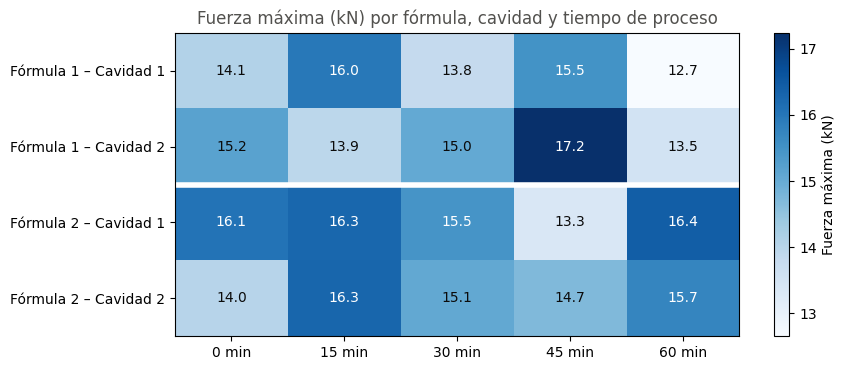

In [44]:
# 8.6 MAPA DE CALOR FÓRMULA – CAVIDAD – TIEMPO
mapa = caso_2024.pivot_table(index=["Fórmula", "Cavidad"], columns="Tiempo_Proceso_min",
                             values="Fuerza_Max_kN")

fig, eje = plt.subplots(figsize=(9, 3.8))
imagen = eje.imshow(mapa.values, cmap="Blues", aspect="auto")

eje.set_xticks(range(mapa.shape[1]))
eje.set_xticklabels([f"{t} min" for t in mapa.columns])
eje.set_yticks(range(mapa.shape[0]))
eje.set_yticklabels([f"Fórmula {f} – Cavidad {c}" for f, c in mapa.index])
eje.axhline(1.5, color="white", linewidth=4)   # separa las dos fórmulas

umbral = mapa.values.min() + (mapa.values.max() - mapa.values.min()) * 0.6
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        valor = mapa.values[i, j]
        eje.text(j, i, f"{valor:.1f}", ha="center", va="center", fontsize=10,
                 color="white" if valor > umbral else "#0b0b0b")

fig.colorbar(imagen, ax=eje, label="Fuerza máxima (kN)")
eje.set_title("Fuerza máxima (kN) por fórmula, cavidad y tiempo de proceso", color=COLOR_TEXTO)
plt.tight_layout()
plt.show()

**Observación:** el mapa de calor no muestra un gradiente de izquierda a derecha (tiempo)
ni una fila que sea siempre más oscura (fórmula o cavidad). El valor más alto es
17,2 kN (Fórmula 1, Cavidad 2, 45 min) y el más bajo 12,7 kN (Fórmula 1, Cavidad 1, 60 min),
ambos de la misma fórmula.

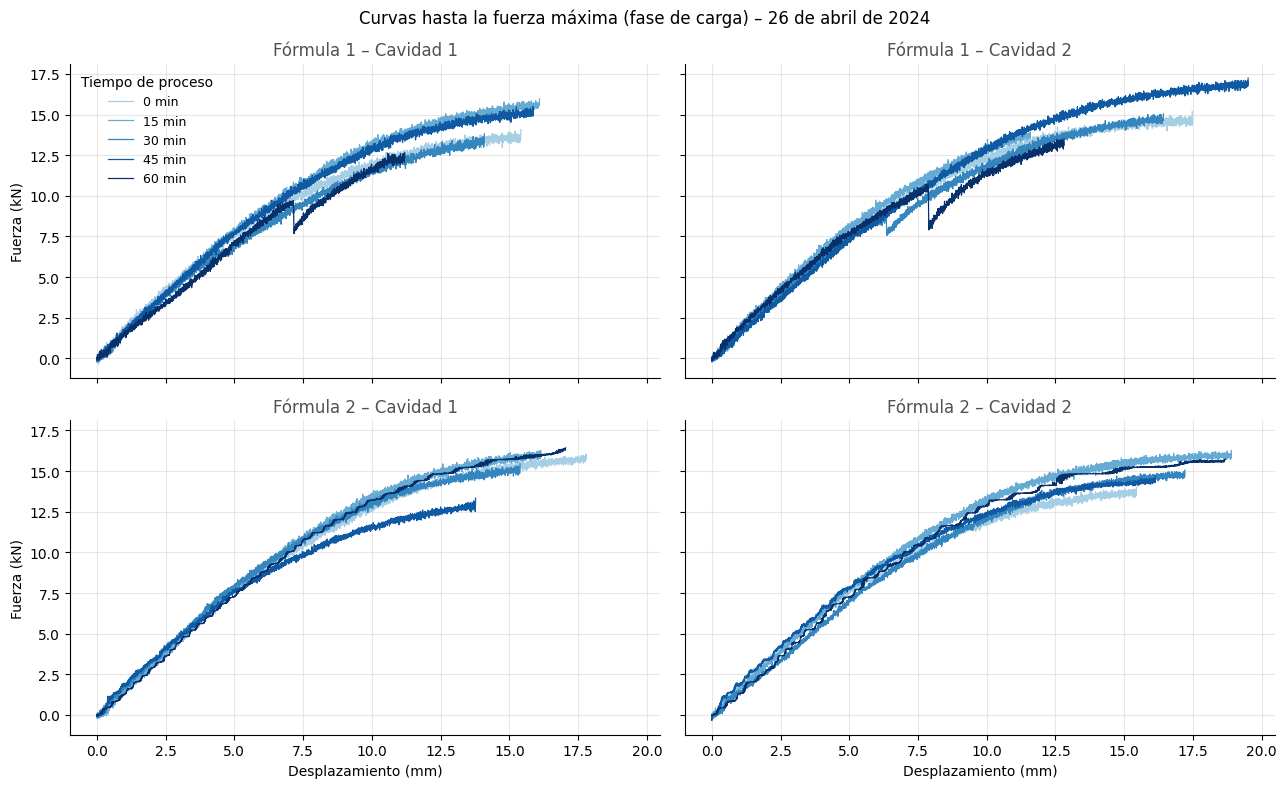

In [45]:
# 8.7 CURVAS FUERZA VS DESPLAZAMIENTO POR FÓRMULA, CAVIDAD Y TIEMPO
tiempos = sorted(caso_2024["Tiempo_Proceso_min"].unique())
colores_tiempo = dict(zip(tiempos, plt.cm.Blues(np.linspace(0.35, 1, len(tiempos)))))

fig, ejes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)

for fila_ejes, formula in zip(ejes, sorted(caso_2024["Fórmula"].unique())):
    for eje, cavidad in zip(fila_ejes, sorted(caso_2024["Cavidad"].unique())):
        grupo = caso_2024[(caso_2024["Fórmula"] == formula) & (caso_2024["Cavidad"] == cavidad)]
        for _, ensayo in grupo.iterrows():
            curva = datos_experimentales[(datos_experimentales["ID_Ensayo"] == ensayo["ID_Ensayo"])
                                         & (datos_experimentales["Fase"] == "Carga")]
            eje.plot(curva["Desplazamiento_mm"], curva["Fuerza_kN"], linewidth=0.9,
                     color=colores_tiempo[ensayo["Tiempo_Proceso_min"]],
                     label=f"{ensayo['Tiempo_Proceso_min']} min")
        eje.set_title(f"Fórmula {formula} – Cavidad {cavidad}", color=COLOR_TEXTO)
        eje.grid(alpha=0.3)
        eje.spines[["top", "right"]].set_visible(False)

for eje in ejes[1]:
    eje.set_xlabel("Desplazamiento (mm)")
for eje in ejes[:, 0]:
    eje.set_ylabel("Fuerza (kN)")
ejes[0, 0].legend(title="Tiempo de proceso", frameon=False, fontsize=9)

fig.suptitle("Curvas hasta la fuerza máxima (fase de carga) – 26 de abril de 2024")
plt.tight_layout()
plt.show()

**Observación:** en cada combinación de fórmula y cavidad, las curvas de los distintos
tiempos siguen prácticamente la misma trayectoria hasta unos 5 mm; después se separan y
terminan a distintos desplazamientos (entre 11 y 19,5 mm). La fuerza máxima depende
principalmente de hasta dónde llega cada curva antes de fallar. En la Fórmula 1 se observan
curvas con una caída brusca de fuerza entre 6 y 8 mm, que luego continúan a menor nivel y
terminan antes; se verifica en la siguiente celda.

In [46]:
# 8.8 PROMEDIOS POR VARIABLE Y REFERENCIA DE REPETIBILIDAD
print("FUERZA MÁXIMA (kN) PROMEDIADA POR CADA VARIABLE")
for variable in ["Fórmula", "Cavidad", "Tiempo_Proceso_min"]:
    print(f"\n{variable}")
    print(caso_2024.groupby(variable)["Fuerza_Max_kN"].agg(["count", "mean", "std", "min", "max"])
          .round(2).to_string())

# Ensayos SIN PLA 1339: muestra y contramuestra de la misma cavidad, mismo día y misma condición
referencia_2024 = campana_abr[campana_abr["Condición"] == "REGULAR ESTANDAR SIN PLA 1339"]
print("\nENSAYOS DE REFERENCIA (REGULAR ESTANDAR SIN PLA 1339)")
print(referencia_2024[["Muestra", "Cavidad", "Contramuestra", "Fuerza_Max_kN",
                       "Desplazamiento_en_Fmax_mm"]].round(3).to_string(index=False))

repetibilidad = referencia_2024.groupby("Cavidad")["Fuerza_Max_kN"].agg(lambda f: f.max() - f.min())
print("\nDIFERENCIA ENTRE MUESTRA Y CONTRAMUESTRA DE LA MISMA CAVIDAD (kN)")
print(repetibilidad.round(3).to_string())

FUERZA MÁXIMA (kN) PROMEDIADA POR CADA VARIABLE

Fórmula
         count   mean   std    min    max
Fórmula                                  
1           10  14.69  1.35  12.65  17.24
2           10  15.33  1.05  13.34  16.42

Cavidad
         count   mean   std    min    max
Cavidad                                  
1           10  14.95  1.36  12.65  16.42
2           10  15.07  1.14  13.50  17.24

Tiempo_Proceso_min
                    count   mean   std    min    max
Tiempo_Proceso_min                                  
0                       4  14.83  0.98  14.01  16.05
15                      4  15.61  1.13  13.93  16.28
30                      4  14.84  0.71  13.81  15.45
45                      4  15.19  1.63  13.34  17.24
60                      4  14.58  1.79  12.65  16.42

ENSAYOS DE REFERENCIA (REGULAR ESTANDAR SIN PLA 1339)
Muestra Cavidad  Contramuestra  Fuerza_Max_kN  Desplazamiento_en_Fmax_mm
      1       1          False         15.772                     16.121
      

**Observación:** al promediar por cada variable, las diferencias son pequeñas: Fórmula 2
supera a Fórmula 1 en 0,64 kN (menos que la desviación estándar de cada grupo), las
cavidades difieren en 0,12 kN y los promedios por tiempo están entre 14,58 y 15,61 kN sin
un orden creciente ni decreciente. Los ensayos de referencia SIN PLA 1339 muestran que
muestra y contramuestra de la misma cavidad difieren solo 0,23–0,29 kN, mucho menos que las
diferencias del diseño principal (hasta 3,7 kN). Sin embargo, esta referencia se basa en
dos pares de otra condición, y en 2022 las muestras de una misma fórmula difirieron entre
1,3 y 3,9 kN; por lo tanto, no es posible separar con seguridad el efecto de la condición
de la variabilidad entre piezas.

In [47]:
# 8.9 CAÍDAS BRUSCAS DE FUERZA DURANTE LA CARGA
UMBRAL_CAIDA_KN = 1.5

def caida_maxima(id_ensayo):
    """Mayor disminución de fuerza en 0,5 s (10 puntos) durante la fase de carga, con la
    fuerza suavizada (media móvil de 5 puntos) para no confundir ruido con caída."""
    curva = datos_experimentales[(datos_experimentales["ID_Ensayo"] == id_ensayo)
                                 & (datos_experimentales["Fase"] == "Carga")]
    cambio = curva["Fuerza_kN"].rolling(5, center=True).mean().diff(10)
    posicion = cambio.idxmin()
    return pd.Series({"Caida_Max_kN": -cambio.min(),
                      "Desplazamiento_Caida_mm": curva.loc[posicion, "Desplazamiento_mm"]})

caso_2024[["Caida_Max_kN", "Desplazamiento_Caida_mm"]] = caso_2024["ID_Ensayo"].apply(caida_maxima)
caso_2024["Caida_Brusca"] = caso_2024["Caida_Max_kN"] > UMBRAL_CAIDA_KN

print("ENSAYOS ORDENADOS POR FUERZA MÁXIMA")
print(caso_2024.sort_values("Fuerza_Max_kN")[["Fórmula", "Cavidad", "Tiempo_Proceso_min", "Fuerza_Max_kN",
                                              "Desplazamiento_en_Fmax_mm", "Caida_Max_kN",
                                              "Desplazamiento_Caida_mm", "Caida_Brusca"]]
      .round(2).to_string(index=False))

print("\nFUERZA MÁXIMA SEGÚN PRESENCIA DE CAÍDA BRUSCA")
print(caso_2024.groupby("Caida_Brusca")["Fuerza_Max_kN"].agg(["count", "mean", "min", "max"]).round(2).to_string())

ENSAYOS ORDENADOS POR FUERZA MÁXIMA
Fórmula Cavidad  Tiempo_Proceso_min  Fuerza_Max_kN  Desplazamiento_en_Fmax_mm  Caida_Max_kN  Desplazamiento_Caida_mm  Caida_Brusca
      1       1                  60          12.65                      11.19          1.77                     7.18          True
      2       1                  45          13.34                      13.77          0.23                    12.41         False
      1       2                  60          13.50                      12.81          2.40                     7.90          True
      1       1                  30          13.81                      14.09          0.31                    10.87         False
      1       2                  15          13.93                      11.59          0.25                    10.08         False
      2       2                   0          14.01                      15.44          0.23                    11.73         False
      1       1                   0          14

**Observación:** solo dos ensayos presentan una caída brusca de fuerza durante la carga
(más de 1,5 kN en 0,5 s): Fórmula 1 a 60 min en la Cavidad 1 (caída de 1,77 kN a 7,2 mm) y
en la Cavidad 2 (2,40 kN a 7,9 mm). Ambos tienen fuerzas máximas bajas (12,65 y 13,50 kN),
frente a una media de 15,23 kN en los ensayos sin caída. Al ocurrir en las dos cavidades
de la misma condición, es el patrón más consistente del caso; con un solo ensayo por
cavidad no puede determinarse si se debe a la condición (Fórmula 1 con 60 min) o a un
evento del ensayo, por lo que se señala como un aspecto a verificar con más ensayos.

### Preguntas de análisis – Caso 2024

**1. ¿La fuerza máxima permanece constante o cambia con el tiempo?**
En promedio permanece aproximadamente constante: los promedios por tiempo están entre
14,58 y 15,61 kN, sin una tendencia creciente ni decreciente, y las rectas ajustadas tienen
R² ≤ 0,16 (pendiente prácticamente nula al unir ambas cavidades). Los ensayos individuales sí
varían entre tiempos consecutivos (hasta 3,7 kN), pero en forma de zigzag, por lo que esa
variación no se explica por el tiempo de proceso.

**2. ¿El comportamiento es igual para las dos fórmulas?**
No exactamente. Entre 0 y 60 min la Fórmula 1 disminuye en ambas cavidades (-1,43 y
-1,69 kN), mientras que la Fórmula 2 aumenta en ambas (+0,37 y +1,72 kN). Además, la
Fórmula 2 tiene un promedio algo mayor (15,33 frente a 14,69 kN), menor dispersión
(desviación 1,05 frente a 1,35 kN), no presenta caídas bruscas y supera a la Fórmula 1 en
7 de 10 pares de igual cavidad y tiempo (prueba de signos p = 0,344). Sin embargo, la ventaja
no es constante: a los 45 min la Fórmula 1 es mayor en ambas cavidades (≈2,2 y 2,5 kN); la
diferencia entre 0 y 60 min de la Fórmula 1 depende de los dos ensayos de 60 min, que
presentan caídas bruscas; y la diferencia promedio entre fórmulas (0,64 kN) es menor que la
dispersión de cada una. Se describe como una tendencia observada, no como una diferencia
demostrada.

**3. ¿Existen diferencias sistemáticas entre Cavidad 1 y Cavidad 2?**
No. Los promedios son casi iguales (14,95 y 15,07 kN). En la Fórmula 1 la Cavidad 2 fue
mayor en 4 de 5 tiempos, pero en la Fórmula 2 solo en 2 de 5. En total la Cavidad 2 superó
a la Cavidad 1 en 6 de 10 pares (prueba de signos p = 0,754).

**4. ¿Las diferencias entre cavidades se mantienen en todos los tiempos?**
No. La diferencia Cavidad 2 – Cavidad 1 cambia de signo según el tiempo: en la Fórmula 1 es
positiva en 4 tiempos pero -2,03 kN a los 15 min, y en la Fórmula 2 cambia de signo tres
veces (de -2,05 kN a 0 min a +1,37 kN a 45 min). Su tamaño va de 0,01 a 2,05 kN.

**5. Ensayo con mayor y menor fuerza máxima**
- Mayor: Fórmula 1, Cavidad 2, 45 min (muestra 12): 17,24 kN, con un desplazamiento de
  19,50 mm, el mayor del subconjunto.
- Menor: Fórmula 1, Cavidad 1, 60 min (muestra 13): 12,65 kN, a 11,19 mm, con una caída
  brusca de fuerza a 7,2 mm.
Ambos pertenecen a la Fórmula 1, que es la fórmula con mayor rango (4,59 kN).

**6. ¿La condición con el mayor valor individual es necesariamente la mejor?**
No. El valor de 17,24 kN proviene de un único ensayo sin repetición: en la misma fórmula y
cavidad, el ensayo de 60 min bajó a 13,50 kN y el de 15 min fue 13,93 kN, y a los 45 min la
otra cavidad alcanzó 15,49 kN. Además, la fórmula que tiene el valor más alto también tiene
el más bajo. Sin repeticiones de cada combinación no es posible saber si 17,24 kN refleja
el efecto de la condición o la variabilidad entre piezas. Para elegir la mejor condición de
proceso se necesitarían varios ensayos por combinación (al menos 3), comparar promedios y
dispersión, y considerar también el desplazamiento y la presencia de fallas anticipadas,
como las caídas bruscas observadas en la Fórmula 1 a 60 min.

**Síntesis del caso 2024:** con estos 20 ensayos no se observa un efecto claro del tiempo de
proceso ni de la cavidad sobre la fuerza máxima, y tampoco una fórmula superior en todos los
tiempos: la Fórmula 2 supera a la Fórmula 1 en 7 de 10 pares de igual cavidad y tiempo, pero a
los 45 min ocurre lo contrario en ambas cavidades. El patrón más consistente es que los dos
ensayos de Fórmula 1 a 60 min (uno por cavidad) presentan una caída brusca de fuerza y las
fuerzas máximas más bajas de esa fórmula. Son tendencias observadas que deberían confirmarse
con ensayos repetidos, no conclusiones estadísticas.

## 9. Análisis de comparabilidad 2022–2024

Antes de comparar los dos años se revisa, con los datos disponibles, si los ensayos se
realizaron bajo condiciones equivalentes: configuración del equipo, información registrada
en los comentarios del encabezado y composición de los ensayos de cada año.

In [48]:
# 9.1 CONFIGURACIÓN DEL ENSAYO Y COMENTARIOS DEL ENCABEZADO
def configuracion_ensayo(ruta_archivo):
    """Extrae la configuración del equipo (línea 1 del archivo) y los comentarios del encabezado."""
    lineas = leer_lineas(ruta_archivo)
    valores = [v.strip() for v in lineas[1].split("\t")]

    # Comentarios: líneas entre el título (Title / Titulo) y la forma de la probeta (Shape: / Forma:)
    comentarios = []
    for linea in lineas[2:]:
        primera = linea.split("\t")[0].strip()
        if primera in ("Shape:", "Forma:"):
            break
        if primera not in ("Title", "Titulo"):
            texto = " ".join(p.strip() for p in linea.split("\t") if p.strip())
            if texto:
                comentarios.append(texto)

    return {
        "Control": valores[3] if len(valores) > 3 else np.nan,
        "Velocidad_1": valores[4] if len(valores) > 4 else np.nan,
        "Origen_Desplazamiento": valores[9] if len(valores) > 9 else np.nan,
        "Comentario": " | ".join(comentarios)
    }

configuracion = pd.DataFrame([configuracion_ensayo(ruta_dataset / r) for r in inventario_ensayos["Ruta"]])
configuracion.insert(0, "ID_Ensayo", inventario_ensayos["ID_Ensayo"].values)
configuracion = configuracion.merge(
    inventario_ensayos[["ID_Ensayo", "Año", "Fecha_Campaña", "Componente", "Tipo_Ensayo"]], on="ID_Ensayo"
)

print("CONFIGURACIÓN DEL EQUIPO POR CAMPAÑA")
print(configuracion.groupby(["Año", "Fecha_Campaña", "Tipo_Ensayo", "Control", "Velocidad_1",
                             "Origen_Desplazamiento"]).size().to_string())

PALABRAS_CLAVE = {
    "Diseño_nuevo": r"DISE[ÑN]O NUEVO",
    "Homologación": r"HOMOLOGACI",
    "Patrón": r"PATR[OÓ]N",
    "Estándar": r"EST[AÁ]NDAR"
}
for etiqueta, patron in PALABRAS_CLAVE.items():
    configuracion[etiqueta] = configuracion["Comentario"].str.upper().str.contains(patron, regex=True)

print("\nARCHIVOS CUYO ENCABEZADO MENCIONA CADA PALABRA CLAVE")
print(configuracion.groupby(["Año", "Fecha_Campaña"])[list(PALABRAS_CLAVE)].sum().to_string())

print("\nCOMENTARIO DEL PRIMER ARCHIVO DE CADA CAMPAÑA")
for fecha, grupo in configuracion.groupby("Fecha_Campaña"):
    print(f"\n{fecha.date()}: {grupo['Comentario'].iloc[0]}")

CONFIGURACIÓN DEL EQUIPO POR CAMPAÑA
Año   Fecha_Campaña  Tipo_Ensayo  Control       Velocidad_1  Origen_Desplazamiento
2022  2022-03-10     Tensión      Stroke        5            Start                     6
      2022-04-06     Tensión      Stroke        10           Start                     2
                                                5            Start                     7
      2022-09-08     Compresión   Stroke        10           Start                     5
                     Tensión      Stroke        5            Start                     5
      2022-10-04     Compresión   Stroke        10           Start                     7
                     Tensión      Stroke        5            Start                     9
      2022-11-11     Tensión      Stroke        5            Start                     3
2024  2024-01-18     Tensión      Stroke        5            Start                    35
      2024-01-23     Tensión      Stroke        5            Start             

**Observación sobre la configuración y los encabezados:** los 114 archivos de 2024 indican
"DISEÑO NUEVO - HOMOLOGACIÓN" y ningún archivo de 2022 lo hace, por lo que las cadenas de 2024
corresponden a un diseño diferente. La configuración del equipo también cambia: el origen del
desplazamiento es "Start" en 2022 y en enero de 2024, pero "Off" desde febrero de 2024
(coincidiendo con el cambio del software a español), y dos ensayos de abril de 2022 se
realizaron a velocidad 10 en lugar de 5. Además, los comentarios contienen condiciones que no
aparecen en el nombre del archivo (por ejemplo, "AZUL" en las campañas de marzo de 2024).

In [49]:
# 9.2 PROMEDIO GENERAL VS PROMEDIO CONTROLADO
print("FUERZA MÁXIMA POR AÑO USANDO TODOS LOS ENSAYOS")
print(resumen_ensayos.groupby("Año")["Fuerza_Max_kN"].agg(["count", "mean", "std", "min", "max"]).round(2).to_string())

print("\nCOMPOSICIÓN DE CADA AÑO")
print(pd.crosstab([resumen_ensayos["Componente"], resumen_ensayos["Referencia"].fillna("-"),
                   resumen_ensayos["Tipo_Ensayo"]], resumen_ensayos["Año"]).to_string())

cadena_1400 = resumen_ensayos[
    (resumen_ensayos["Componente"] == "Cadena") &
    (resumen_ensayos["Referencia"] == "1400") &
    (resumen_ensayos["Tipo_Ensayo"] == "Tensión")
]

print("\nSOLO CADENA 1400 A TENSIÓN")
print(cadena_1400.groupby("Año")["Fuerza_Max_kN"].agg(["count", "mean", "std", "min", "max"]).round(2).to_string())

print("\nCADENA 1400 A TENSIÓN POR CAMPAÑA")
print(cadena_1400.groupby(["Año", "Fecha_Campaña"]).agg(
    N=("Fuerza_Max_kN", "size"),
    Fmax_Media_kN=("Fuerza_Max_kN", "mean"),
    Fmax_Min_kN=("Fuerza_Max_kN", "min"),
    Fmax_Max_kN=("Fuerza_Max_kN", "max"),
    Desp_Fmax_Media_mm=("Desplazamiento_en_Fmax_mm", "mean")
).round(2).to_string())

FUERZA MÁXIMA POR AÑO USANDO TODOS LOS ENSAYOS
      count   mean   std   min    max
Año                                  
2022     44   8.60  5.73  0.60  18.20
2024    114  14.87  2.11  6.82  17.91

COMPOSICIÓN DE CADA AÑO
Año                                2022  2024
Componente Referencia Tipo_Ensayo            
Cadena     1400       Tensión        28   108
           2600       Tensión         0     6
Hebilla    -          Tensión         2     0
Pin        1400       Compresión     12     0
Piñón      1400       Tensión         2     0

SOLO CADENA 1400 A TENSIÓN
      count   mean   std    min    max
Año                                   
2022     28  12.17  3.30   5.38  18.20
2024    108  15.24  1.41  10.74  17.91

CADENA 1400 A TENSIÓN POR CAMPAÑA
                     N  Fmax_Media_kN  Fmax_Min_kN  Fmax_Max_kN  Desp_Fmax_Media_mm
Año  Fecha_Campaña                                                                 
2022 2022-03-10      6          13.44         9.35        18.20    

**Observación:** con todos los ensayos, la fuerza máxima media es 8,60 kN en 2022 y 14,87 kN
en 2024. Pero 2022 incluye pines a compresión, hebillas y piñones, que tienen fuerzas mucho
menores. Al restringir a cadena 1400 a tensión, la diferencia baja de 6,27 a 3,07 kN
(12,17 frente a 15,24 kN): cerca de la mitad de la diferencia inicial se debía solo a la
composición de los ensayos. Las medias por campaña también varían dentro de un mismo año
(de 9,14 a 13,64 kN en 2022).

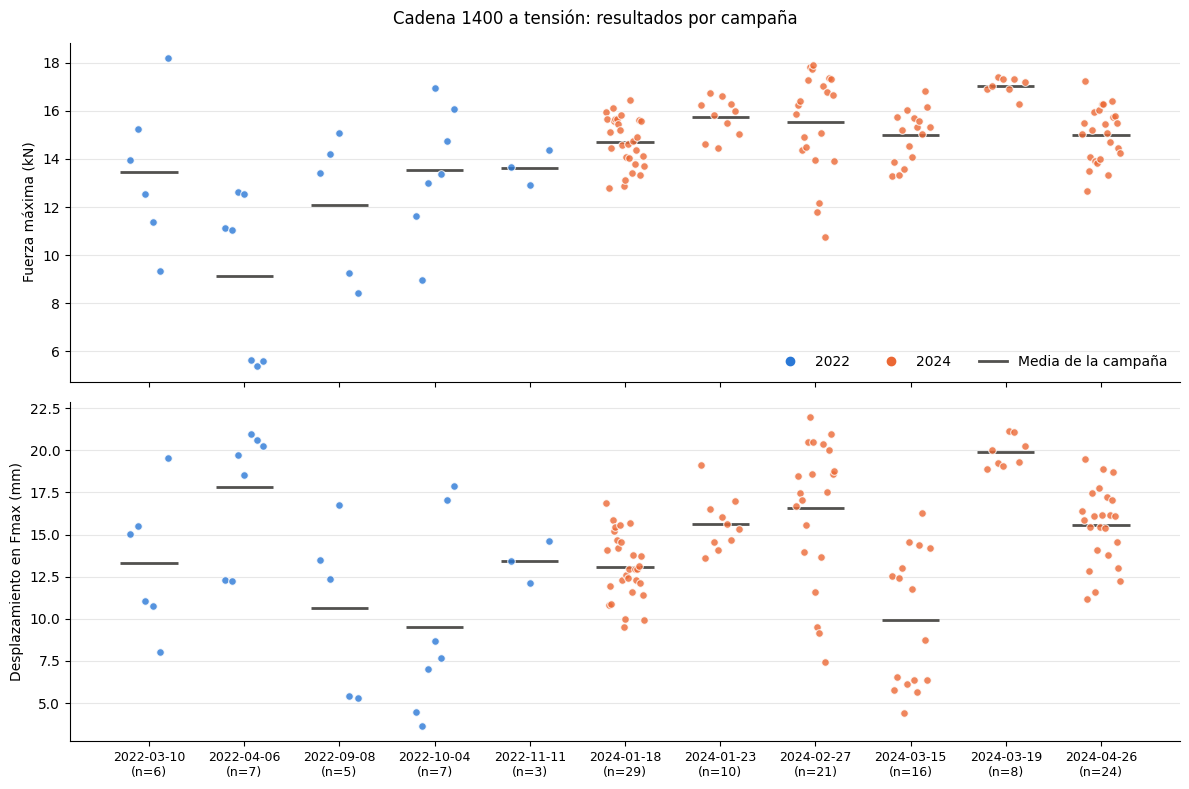

In [50]:
# 9.3 FUERZA MÁXIMA Y DESPLAZAMIENTO POR CAMPAÑA (CADENA 1400 A TENSIÓN)
COLORES_ANIO = {2022: "#2a78d6", 2024: "#eb6834"}
campanas = sorted(cadena_1400["Fecha_Campaña"].unique())

fig, ejes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
variables = [("Fuerza_Max_kN", "Fuerza máxima (kN)"), ("Desplazamiento_en_Fmax_mm", "Desplazamiento en Fmax (mm)")]

for eje, (variable, etiqueta) in zip(ejes, variables):
    for i, fecha in enumerate(campanas):
        grupo = cadena_1400[cadena_1400["Fecha_Campaña"] == fecha]
        anio = grupo["Año"].iloc[0]
        dx = np.linspace(-0.2, 0.2, len(grupo)) if len(grupo) > 1 else [0]
        eje.scatter(i + np.array(dx), grupo[variable], s=30, color=COLORES_ANIO[anio], alpha=0.8,
                    edgecolor="white", linewidth=0.8, zorder=3)
        eje.hlines(grupo[variable].mean(), i - 0.3, i + 0.3, color=COLOR_TEXTO, linewidth=2, zorder=2)
    eje.set_ylabel(etiqueta)
    eje.grid(axis="y", alpha=0.3)
    eje.spines[["top", "right"]].set_visible(False)

ejes[1].set_xticks(range(len(campanas)))
ejes[1].set_xticklabels([f"{pd.Timestamp(f):%Y-%m-%d}\n(n={(cadena_1400['Fecha_Campaña'] == f).sum()})"
                         for f in campanas], fontsize=9)
ejes[0].legend(handles=[
    Line2D([], [], marker="o", linestyle="", color=COLORES_ANIO[2022], label="2022"),
    Line2D([], [], marker="o", linestyle="", color=COLORES_ANIO[2024], label="2024"),
    Line2D([], [], color=COLOR_TEXTO, linewidth=2, label="Media de la campaña")
], frameon=False, ncol=3, loc="lower right")
fig.suptitle("Cadena 1400 a tensión: resultados por campaña")
plt.tight_layout()
plt.show()

**Observación:** todas las medias de las campañas de 2024 (14,72 a 17,05 kN) son mayores que
todas las de 2022 (9,14 a 13,64 kN), y 2024 presenta menor dispersión. Sin embargo, el
desplazamiento en la fuerza máxima no muestra un patrón por año y varía mucho entre campañas:
las campañas del 15 y del 19 de marzo de 2024, con la misma condición nominal, tienen medias
de 9,9 y 19,9 mm. Esto indica que la campaña (día, lote, configuración) influye fuertemente
en los resultados.

### 9.4 Subconjunto razonablemente comparable

Se propone comparar las muestras de referencia de cada año, manteniendo constantes el
componente (cadena 1400), el tipo de ensayo (tensión), la velocidad (5) y el origen del
desplazamiento ("Start"):
- **2022:** muestras patrón (patrón de referencia) de la cadena 1400.
- **2024:** condición estándar de enero (NORMAL ESTANDAR de la cadena 1400 y DISEÑO ESTANDAR),
  únicas campañas de 2024 con la misma configuración del equipo que 2022.
Se compara la fuerza máxima y, como la configuración es la misma, también el desplazamiento
en la fuerza máxima.

Como los patrones de 2022 son pocos y heterogéneos, se agrega un análisis de sensibilidad: la
comparación se repite quitando el patrón marcado con ruido alto (PC21) y el patrón con cambio
de PIN, que no corresponde a una condición de referencia pura.

In [ ]:
# 9.4 SUBCONJUNTO COMPARABLE PROPUESTO
datos_comparables = resumen_ensayos.merge(
    configuracion[["ID_Ensayo", "Velocidad_1", "Origen_Desplazamiento", "Diseño_nuevo"]], on="ID_Ensayo"
)

print("ENSAYOS DE TENSIÓN CON VELOCIDAD DIFERENTE DE 5")
print(datos_comparables[(datos_comparables["Tipo_Ensayo"] == "Tensión") & (datos_comparables["Velocidad_1"] != "5")]
      [["Fecha_Campaña", "Archivo", "Componente", "Velocidad_1"]].to_string(index=False))

base = datos_comparables[
    (datos_comparables["Componente"] == "Cadena") &
    (datos_comparables["Referencia"] == "1400") &
    (datos_comparables["Tipo_Ensayo"] == "Tensión") &
    (datos_comparables["Velocidad_1"] == "5") &
    (datos_comparables["Origen_Desplazamiento"] == "Start")
]
grupo_2022 = base[(base["Año"] == 2022) & (base["Patron"])]
grupo_2024 = base[(base["Año"] == 2024) & (base["Condición"].isin(["NORMAL ESTANDAR", "DISENO ESTANDAR"]))]

subconjunto = pd.concat([
    grupo_2022.assign(Grupo="2022 – Patrón (diseño anterior)"),
    grupo_2024.assign(Grupo="2024 – Estándar (diseño nuevo)")
])

print("\nENSAYOS DEL SUBCONJUNTO")
print(subconjunto[["Grupo", "Fecha_Campaña", "Archivo", "Condición", "Cavidad", "Fuerza_Max_kN",
                   "Desplazamiento_en_Fmax_mm", "Ruido_Alto"]].round(2).to_string(index=False))

print("\nESTADÍSTICOS POR GRUPO")
print(subconjunto.groupby("Grupo")[["Fuerza_Max_kN", "Desplazamiento_en_Fmax_mm"]]
      .agg(["count", "mean", "std", "min", "max"]).round(2).T.to_string())

# Sensibilidad: la comparación se repite cambiando qué patrones de 2022 se incluyen
sin_ruido = grupo_2022[~grupo_2022["Ruido_Alto"]]
sin_ruido_ni_cambio = sin_ruido[~sin_ruido["Condición"].str.contains("CAMBIO", na=False)]
escenarios_2022 = {
    "Todos los patrones": grupo_2022,
    "Sin ruido alto (PC21)": sin_ruido,
    "Sin ruido alto ni cambio de PIN": sin_ruido_ni_cambio
}
fmax_2024 = grupo_2024["Fuerza_Max_kN"]
sensibilidad = pd.DataFrame([{
    "Escenario_2022": escenario,
    "N_2022": len(g),
    "Media_2022_kN": g["Fuerza_Max_kN"].mean(),
    "Mediana_2022_kN": g["Fuerza_Max_kN"].median(),
    "Dif_Medias_kN": fmax_2024.mean() - g["Fuerza_Max_kN"].mean(),
    "Dif_Medianas_kN": fmax_2024.median() - g["Fuerza_Max_kN"].median()
} for escenario, g in escenarios_2022.items()]).set_index("Escenario_2022")

print(f"\nSENSIBILIDAD DE LA COMPARACIÓN (2024: n = {len(fmax_2024)}, media = {fmax_2024.mean():.2f} kN, "
      f"mediana = {fmax_2024.median():.2f} kN; diferencias = 2024 – 2022)")
print(sensibilidad.round(2).to_string())

# Gráfica de puntos de los dos grupos
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
grupos = list(subconjunto["Grupo"].unique())
colores_grupo = [COLORES_ANIO[2022], COLORES_ANIO[2024]]
for eje, (variable, etiqueta) in zip(ejes, variables):
    for i, (grupo, color) in enumerate(zip(grupos, colores_grupo)):
        valores = subconjunto[subconjunto["Grupo"] == grupo][variable]
        dx = np.linspace(-0.12, 0.12, len(valores)) if len(valores) > 1 else [0]
        eje.scatter(i + np.array(dx), valores, s=60, color=color, edgecolor="white", linewidth=1.2, zorder=3)
        eje.hlines(valores.mean(), i - 0.25, i + 0.25, color=COLOR_TEXTO, linewidth=2, zorder=2)
    eje.set_xticks(range(len(grupos)))
    eje.set_xticklabels([g.replace(" – ", "\n") for g in grupos])
    eje.set_ylabel(etiqueta)
    eje.grid(axis="y", alpha=0.3)
    eje.spines[["top", "right"]].set_visible(False)
fig.suptitle("Subconjunto comparable: cadena 1400, tensión, velocidad 5, origen 'Start' (línea = media)")
plt.tight_layout()
plt.show()

**Observación:** toda la cadena a tensión se ensayó a velocidad 5 (solo las hebillas se
ensayaron a 10). En el subconjunto comparable, los patrones de 2022 son muy heterogéneos:
van de 5,59 kN (PC21 patrón, con ruido alto) a 18,20 kN (patrón de referencia de marzo),
mientras que los otros tres están entre 13,40 y 14,19 kN. Los ensayos estándar de enero de
2024 están entre 13,33 y 16,74 kN. La diferencia de medias es 2,02 kN (13,01 frente a
15,03 kN) y la de medianas 1,25 kN (13,65 frente a 14,90 kN); los rangos se superponen.

El análisis de sensibilidad muestra que la diferencia de medias depende de un solo ensayo:
sin el patrón PC21 baja a ≈0,2 kN, y si además se quita el patrón con cambio de PIN se invierte
ligeramente (≈-0,05 kN). La diferencia de medianas es más estable (≈1,0 a 1,25 kN), pero con
3 a 5 patrones tampoco permite afirmar una diferencia. Al controlar más variables, la
diferencia entre años se reduce: 6,27 kN con todos los ensayos, 3,07 kN con cadena 1400 a
tensión y entre ≈0 y 2,02 kN en este subconjunto, según qué patrones de 2022 se incluyan.

### 9.5 Efecto de la campaña dentro de 2024

Las campañas del 15 y 19 de marzo de 2024 tienen la misma condición nominal
(TEMP. 210°C + SALIDA DE AIRE - AZUL), los mismos tiempos y las cavidades 1X3 y 2X3. Se
comparan ensayo a ensayo para estimar cuánto cambian los resultados entre dos campañas
separadas solo por 4 días.

In [52]:
# 9.5 MISMA CONDICIÓN, DOS CAMPAÑAS: 15 Y 19 DE MARZO DE 2024
marzo = resumen_ensayos[
    resumen_ensayos["Fecha_Campaña"].isin([pd.Timestamp("2024-03-15"), pd.Timestamp("2024-03-19")]) &
    resumen_ensayos["Cavidad"].isin(["1X3", "2X3"])
].copy()
marzo["Campaña_Fecha"] = marzo["Fecha_Campaña"].dt.strftime("%Y-%m-%d")

for variable in ["Fuerza_Max_kN", "Desplazamiento_en_Fmax_mm"]:
    pares = marzo.pivot_table(index=["Tiempo_Proceso_min", "Cavidad"], columns="Campaña_Fecha", values=variable)
    pares["Diferencia_19_menos_15"] = pares["2024-03-19"] - pares["2024-03-15"]
    print(f"\n{variable}")
    print(pares.round(2).to_string())
    print(f"El 19 de marzo es mayor en {(pares['Diferencia_19_menos_15'] > 0).sum()} de {len(pares)} pares; "
          f"diferencia media = {pares['Diferencia_19_menos_15'].mean():.2f}")


Fuerza_Max_kN
Campaña_Fecha               2024-03-15  2024-03-19  Diferencia_19_menos_15
Tiempo_Proceso_min Cavidad                                                
0.0                1X3           14.53       16.92                    2.39
                   2X3           14.10       17.03                    2.94
45.0               1X3           15.59       17.39                    1.81
                   2X3           15.06       17.31                    2.25
75.0               1X3           15.31       16.93                    1.62
                   2X3           13.29       17.31                    4.02
120.0              1X3           13.34       16.28                    2.94
                   2X3           15.20       17.19                    2.00
El 19 de marzo es mayor en 8 de 8 pares; diferencia media = 2.49

Desplazamiento_en_Fmax_mm
Campaña_Fecha               2024-03-15  2024-03-19  Diferencia_19_menos_15
Tiempo_Proceso_min Cavidad                                          

**Observación:** con la misma condición nominal, las mismas cavidades, los mismos tiempos y
la misma configuración del equipo, la campaña del 19 de marzo superó a la del 15 de marzo en
los 8 pares comparados, en promedio 2,49 kN en fuerza máxima y 6,22 mm en desplazamiento.
Es decir, dos campañas de 2024 separadas por 4 días difieren tanto o más que los grupos de
2022 y 2024 del subconjunto comparable. Existe un efecto de campaña (lote, día u otras
condiciones no registradas) que impide atribuir la diferencia entre años al diseño o al año.

### Preguntas de análisis – Comparabilidad 2022–2024

**1. ¿Todos los resultados de 2022 pueden compararse directamente con todos los de 2024?**
No. Los datos muestran diferencias que impiden una comparación directa:
- **Diseño:** los 114 archivos de 2024 indican "DISEÑO NUEVO - HOMOLOGACIÓN"; ninguno de 2022.
- **Componentes y tipo de ensayo:** 2022 incluye 12 pines a compresión, 2 hebillas y 2 piñones
  además de 28 cadenas 1400; 2024 incluye 108 cadenas 1400 y 6 cadenas 2600, todas a tensión.
- **Objetivo de las campañas:** en 2022 se comparan lotes, materiales y fórmulas; en 2024,
  condiciones de proceso (calzas, temperatura del agua e inyección, 210 °C con salida de aire,
  tiempos) y cavidades.
- **Configuración del equipo:** el origen del desplazamiento es "Start" en 2022 y enero de
  2024, pero "Off" desde febrero de 2024.
- **Información registrada:** la cavidad no se registró en 2022 y en marzo de 2024 se usa
  otra notación (1X3, 2X3…).

**2. Variables o condiciones que deben controlarse antes de comparar entre años**
1. **Componente y referencia:** cadena 1400 frente a 2600, pin, piñón y hebilla tienen fuerzas
   de distinto orden (≈1 kN en pines y hebillas frente a ≈15 kN en la cadena).
2. **Tipo de ensayo:** tensión y compresión no son comparables.
3. **Diseño de la pieza:** anterior (2022) frente a nuevo (2024).
4. **Condición de fabricación:** patrón o estándar frente a condiciones modificadas (calzas,
   temperatura, tiempo de proceso).
5. **Fórmula:** "Fórmula 1" en 2022 y en 2024 no necesariamente es la misma formulación.
6. **Cavidad:** no registrada en 2022.
7. **Configuración experimental:** velocidad, origen del desplazamiento y geometría registrada.
8. **Campaña o lote:** como se vio el 15 y 19 de marzo de 2024, la campaña por sí sola
   puede cambiar la fuerza máxima en ≈2,5 kN.

**3. Subconjunto razonablemente comparable**
- **Archivos:** 2022, muestras patrón de la cadena 1400 a tensión (10 de marzo, 6 de abril,
  8 de septiembre y 11 de noviembre; 5 ensayos). 2024, condición estándar de enero
  (NORMAL ESTANDAR de la cadena 1400 del 18 de enero y DISEÑO ESTANDAR del 23 de enero;
  7 ensayos).
- **Variable comparada:** fuerza máxima (y desplazamiento en la fuerza máxima, porque ambos
  grupos tienen el mismo origen de desplazamiento).
- **Condiciones constantes:** componente (cadena 1400), tipo de ensayo (tensión), velocidad 5,
  origen del desplazamiento "Start", misma geometría registrada y condición de referencia
  (sin modificaciones de proceso).
- **Resultado:** 13,01 kN (mediana 13,65) en 2022 frente a 15,03 kN (mediana 14,90) en 2024,
  con rangos superpuestos. Si se excluye el patrón PC21 (ruido alto, 5,59 kN), la diferencia
  de medias baja de 2,02 a ≈0,2 kN, y si también se excluye el patrón con cambio de PIN se
  invierte ligeramente (≈-0,05 kN).
- **Limitaciones:** el diseño es diferente, por lo que la comparación mezcla el efecto del
  diseño con el del tiempo, el lote y el proceso; los "patrones" de 2022 son heterogéneos
  (5,59 a 18,20 kN) y no está documentado qué representan; solo hay 5 y 7 ensayos, y la
  diferencia de medias depende de un solo ensayo; la cavidad de 2022 es desconocida; y la
  diferencia entre grupos (entre ≈0 y 2,02 kN) es menor que la diferencia observada entre dos
  campañas de 2024 con la misma condición (2,49 kN).

Por lo tanto, este subconjunto controla las condiciones del ensayo, pero no las del producto.
Solo permite describir que las cadenas estándar del diseño nuevo alcanzaron fuerzas máximas
similares o algo mayores que la mayoría de los patrones de 2022, sin poder atribuir esa
diferencia al diseño.

**4. ¿Por qué comparar solo el promedio de 2022 con el de 2024 puede ser incorrecto?**
- **Composición distinta:** el promedio de 2022 (8,60 kN) incluye pines y hebillas de ≈1 kN;
  solo por eso la diferencia con 2024 (14,87 kN) se duplica.
- **Factores mezclados:** la diferencia pasa de 6,27 kN con todos los ensayos a 3,07 kN con
  cadena 1400 a tensión y a entre ≈0 y 2,02 kN en el subconjunto comparable; gran parte de la
  diferencia proviene de qué se ensayó y no del año.
- **Pesos desiguales:** 2024 tiene 114 ensayos concentrados en pocas campañas (29 el 18 de
  enero y 24 el 26 de abril), y cada campaña estudia condiciones distintas.
- **Efecto de campaña:** campañas del mismo año con la misma condición difieren en ≈2,5 kN.
- **El promedio oculta la dispersión y es sensible a valores atípicos:** en cadena 1400 la
  desviación es 3,30 kN en 2022 y 1,41 kN en 2024, y en el subconjunto comparable un solo
  ensayo cambia la diferencia de medias de 2,02 a ≈0,2 kN.

**Conclusión:** con los datos disponibles no es posible una comparación directa
suficientemente controlada entre 2022 y 2024. Las diferencias de diseño, condiciones,
configuración y campaña se superponen, y el efecto de campaña es del mismo tamaño que la
diferencia entre años.

## 10. Conclusiones

Las conclusiones se apoyan en los indicadores de la siguiente tabla, calculados directamente
a partir de los resultados de las secciones anteriores.

In [ ]:
# 10.1 EVIDENCIA CUANTITATIVA DE LAS CONCLUSIONES
def rango(serie_min, serie_max):
    """Une los mínimos y máximos de cada grupo en un texto 'mín–máx / mín–máx'."""
    return " / ".join(f"{a:.1f}–{b:.1f}" for a, b in zip(serie_min, serie_max))

# Las medias se redondean a 2 decimales, igual que en las tablas de las secciones 8 y 9,
# para que los valores de esta tabla coincidan con los citados en el texto
medias_tiempo = caso_2024.groupby("Tiempo_Proceso_min")["Fuerza_Max_kN"].mean().round(2)
caidas = caso_2024[caso_2024["Caida_Brusca"]]
mayor_salto = (caso_2024.sort_values("Tiempo_Proceso_min")
               .groupby(["Fórmula", "Cavidad"])["Fuerza_Max_kN"].diff().abs().max())
pares_marzo = marzo.pivot_table(index=["Tiempo_Proceso_min", "Cavidad"], columns="Campaña_Fecha",
                                values="Fuerza_Max_kN")
dif_marzo = (pares_marzo["2024-03-19"] - pares_marzo["2024-03-15"]).mean()
dif_todos = resumen_ensayos.groupby("Año")["Fuerza_Max_kN"].mean().round(2).diff().iloc[-1]
dif_cadena = cadena_1400.groupby("Año")["Fuerza_Max_kN"].mean().round(2).diff().iloc[-1]
dif_subconjunto = subconjunto.groupby("Año")["Fuerza_Max_kN"].mean().round(2).diff().iloc[-1]
dif_sin_pc21 = sensibilidad.loc["Sin ruido alto (PC21)", "Dif_Medias_kN"]
config_2024 = configuracion[configuracion["Año"] == 2024]
pct_negativos_post = curvas.loc[curvas["Fuerza_Negativa"], "Fase"].eq("Post_Fmax").mean() * 100
ruido_componente = diagnostico.groupby("Componente")["Oscilacion_vs_Fmax_pct"].median()
anio_2022 = inventario_ensayos["Año"] == 2022

evidencia = pd.DataFrame([
    ("1. Caso 2022", "Fuerza máxima F1 / F2 / F3 (kN, mín–máx)",
     rango(estadisticos_2022["Fmax_Min_kN"], estadisticos_2022["Fmax_Max_kN"])),
    ("1. Caso 2022", "Desplazamiento en Fmax F1 / F2 / F3 (mm, mín–máx)",
     rango(estadisticos_2022["Desp_Fmax_Min_mm"], estadisticos_2022["Desp_Fmax_Max_mm"])),
    ("2. Abril 2024", "Media de Fmax por tiempo de proceso (kN, mín–máx)",
     f"{medias_tiempo.min():.2f}–{medias_tiempo.max():.2f}"),
    ("2. Abril 2024", "R² máximo de la tendencia Fmax–tiempo", f"{tendencias_2024['R2'].max():.2f}"),
    ("2. Abril 2024", "Pares con Cavidad 2 > Cavidad 1", f"{veces_cav2} de {total_pares}"),
    ("2. Abril 2024", "Pares con Fórmula 2 > Fórmula 1 (misma cavidad y tiempo)",
     f"{veces_f2} de {len(pares_formula)}"),
    ("2. Abril 2024", "Ensayos con caída brusca de fuerza",
     ", ".join(f"F{f}-Cav{c}-{t} min" for f, c, t in
               zip(caidas["Fórmula"], caidas["Cavidad"], caidas["Tiempo_Proceso_min"]))),
    ("3. Variabilidad", "Rango de Fmax dentro de una fórmula, 2022 (kN)",
     f"{estadisticos_2022['Fmax_Rango_kN'].min():.2f}–{estadisticos_2022['Fmax_Rango_kN'].max():.2f}"),
    ("3. Variabilidad", "Mayor salto entre tiempos consecutivos, abril 2024 (kN)", f"{mayor_salto:.2f}"),
    ("3. Variabilidad", "Diferencia media 19 vs 15 de marzo 2024, misma condición (kN)", f"{dif_marzo:.2f}"),
    ("3. Variabilidad", "Muestra vs contramuestra SIN PLA 1339, misma cavidad (kN)",
     f"{repetibilidad.min():.2f}–{repetibilidad.max():.2f}"),
    ("4. Comparabilidad", "Archivos de 2024 con 'DISEÑO NUEVO'",
     f"{int(config_2024['Diseño_nuevo'].sum())} de {len(config_2024)}"),
    ("4. Comparabilidad", "Diferencia de medias 2024 – 2022: todos / cadena 1400 / subconjunto (kN)",
     f"{dif_todos:.2f} / {dif_cadena:.2f} / {dif_subconjunto:.2f}"),
    ("4. Comparabilidad", "Diferencia de medias del subconjunto sin el patrón PC21 (ruido alto) (kN)",
     f"{dif_sin_pc21:.2f}"),
    ("5. Limitaciones", "Ensayos con geometría de relleno",
     f"{int((~resumen_equipo['Geometria_Real']).sum())} de {len(resumen_equipo)}"),
    ("5. Limitaciones", "Ensayos de 2022 sin cavidad registrada",
     f"{int(inventario_ensayos.loc[anio_2022, 'Cavidad'].isna().sum())} de {int(anio_2022.sum())}"),
    ("5. Limitaciones", "Archivos .pdf no procesables", f"{int((lista_archivos['Extension'] == '.pdf').sum())}"),
    ("5. Limitaciones", "Ensayos por combinación en abril 2024", f"{int(verificacion.max().max())}"),
    ("6. Calidad de la señal", "Valores de fuerza negativos que ocurren después de Fmax",
     f"{pct_negativos_post:.1f}%"),
    ("6. Calidad de la señal", "Ruido inicial / Fmax, mediana: cadena / pin / hebilla (%)",
     f"{ruido_componente['Cadena']:.1f} / {ruido_componente['Pin']:.1f} / {ruido_componente['Hebilla']:.1f}")
], columns=["Conclusión", "Indicador", "Valor"])

print("EVIDENCIA CUANTITATIVA DE LAS CONCLUSIONES")
print(evidencia.to_string(index=False))

### Conclusiones

**1. Caso 2022 – Las fórmulas se diferencian más por el desplazamiento que por la fuerza
máxima.** En los ensayos de tensión del 4 de octubre de 2022, el desplazamiento en la fuerza
máxima no se superpone entre fórmulas (Fórmula 1: 3,6–4,5 mm; Fórmula 2: 7,0–8,7 mm;
Fórmula 3: 17,1–17,9 mm), mientras que la fuerza máxima de las Fórmulas 2 (13,0–16,9 kN) y 3
(14,8–16,1 kN) sí se superpone. La Fórmula 1 registró las fuerzas más bajas (9,0–11,6 kN).
El mayor valor individual (16,94 kN, Fórmula 2) no implica que esa fórmula sea superior: la
Fórmula 3 tiene mayor media (15,42 frente a 14,45 kN) y menor variabilidad (CV 6,1% frente a
15,0%). Con 2 o 3 ensayos por fórmula, esto se presenta como una tendencia.
*Evidencia: tabla 7.3, gráficas 7.4 y 7.5.*

**2. Abril 2024 – No se encontró un efecto consistente del tiempo de proceso, de la cavidad
ni de la fórmula.** Las medias por tiempo varían solo entre 14,58 y 15,61 kN sin orden
creciente ni decreciente, y ninguna tendencia lineal supera R² = 0,16. Las cavidades tienen
medias de 14,95 y 15,07 kN, y la Cavidad 2 supera a la Cavidad 1 en 6 de 10 pares (prueba de
signos p = 0,754). La Fórmula 2 supera a la Fórmula 1 en 7 de 10 pares (p = 0,344), pero a los
45 min ocurre lo contrario en ambas cavidades. El patrón más consistente es que los dos ensayos
de Fórmula 1 a 60 min (uno por cavidad) presentaron una caída brusca de fuerza (1,77 y
2,40 kN) y las fuerzas máximas más bajas de esa fórmula (12,65 y 13,50 kN, frente a 15,23 kN
de media en los ensayos sin caída); con un solo ensayo por combinación, debe verificarse con
repeticiones.
*Evidencia: tablas 8.3, 8.4, 8.5, 8.8 y 8.9; gráficas 8.5, 8.6 y 8.7.*

**3. Variabilidad – La variación entre piezas y entre campañas es del mismo orden que las
diferencias entre condiciones.** Dentro de una misma fórmula de 2022, la fuerza máxima varió
entre 1,32 y 3,92 kN; en abril de 2024 hubo saltos de hasta 3,74 kN entre tiempos
consecutivos; y dos campañas de marzo de 2024 con la misma condición nominal difirieron en
promedio 2,49 kN (8 de 8 pares en el mismo sentido). En cambio, muestra y contramuestra de
la condición SIN PLA 1339 difirieron solo 0,23–0,29 kN. Esta contradicción, con tan pocos
datos, impide estimar con confianza la repetibilidad y, por lo tanto, separar el efecto de
cada condición de la variabilidad propia de las piezas.
*Evidencia: tablas 7.3, 8.3, 8.8 y 9.5.*

**4. Comparabilidad – Los datos de 2022 y 2024 no permiten una comparación directa
controlada.** Los 114 archivos de 2024 corresponden a un "DISEÑO NUEVO", y la diferencia
entre años se reduce a medida que se controlan variables: 6,27 kN con todos los ensayos,
3,07 kN con cadena 1400 a tensión y 2,02 kN en el subconjunto comparable (patrones de 2022
frente a estándar de enero de 2024, con igual velocidad y origen de desplazamiento). Esta
última diferencia depende de un solo ensayo: sin el patrón PC21 (ruido alto, 5,59 kN) baja a
≈0,2 kN. Además, es menor que la observada entre dos campañas de 2024 con la misma condición
(2,49 kN), por lo que no puede atribuirse al diseño ni al año.
*Evidencia: tablas 9.1, 9.2, 9.4 (incluida la sensibilidad) y 9.5; gráfica 9.3.*

**5. Limitaciones del conjunto de datos.** 144 de los 158 ensayos tienen una geometría de
relleno (1 × 1 × 100 mm), por lo que no se puede calcular el esfuerzo real; el equipo no
registró la rotura en ningún ensayo; la cavidad no se registró en ninguno de los 44 ensayos
de 2022; la campaña del 6–7 de febrero de 2024 solo tiene 26 archivos .pdf que no se pueden
procesar; el origen del desplazamiento cambió de "Start" a "Off" desde febrero de 2024; y en
abril de 2024 hay un solo ensayo por combinación. Estas limitaciones restringen el análisis
a la fuerza máxima y obligan a presentar los resultados como tendencias y no como
diferencias demostradas.
*Evidencia: tablas 3.6, 4.12, 5.6, 5.7, 8.2 y 9.1.*

**6. Calidad de la señal – Los valores negativos iniciales son ruido y no se eliminaron; el
ruido limita la confiabilidad de algunos componentes.** La fuerza tiene una oscilación de
≈0,5 kN durante todo el ensayo, y solo el 0,8% de los puntos de la fase de carga son negativos.
El 78,1% de los valores negativos ocurre después de la fuerza máxima, cuando la pieza ya falló
(hasta -5 kN); esos no son ruido sino parte del registro posterior a la falla, y se
identifican con la columna Fase. Respecto a la fuerza máxima, el ruido es pequeño en la cadena
(mediana 3,6%) pero comparable a la señal en pines (44,8%) y hebillas (82,7%), por lo que los
resultados de estos componentes deben interpretarse con precaución.
*Evidencia: tablas 5.8 y 5.10; gráfica 5.9.*

### Recomendaciones
- Realizar al menos 3 ensayos por cada combinación de condiciones para poder estimar la
  variabilidad y aplicar pruebas estadísticas.
- Registrar la geometría real de la pieza, la cavidad y todas las condiciones de proceso
  en el archivo, no solo en el nombre.
- Mantener la misma configuración del equipo (origen del desplazamiento, velocidad) en
  todas las campañas que se quieran comparar.
- Incluir en cada campaña ensayos de una condición de referencia común para poder
  comparar campañas y años.